# Airbnb Listing Price Prediction
### AnalystLab Africa — Machine Learning Track

**Project objective:** develop and evaluate city-specific machine learning models to estimate Airbnb advertised listing prices.

This notebook presents the completed workflow and its evidence. The original implementation remains in `src/`; this notebook does not modify those scripts or retrain the final models.

> **Reproducibility note:** Most results below are loaded from reports generated by the original scripts. Run the notebook from the project environment, with the repository structure intact. Cells that load reports reproduce the presentation of existing results; they do not regenerate the original analyses.

## Contents
1. Business problem and prediction scenario
2. Dataset overview
3. Data quality audit
4. Exploratory price analysis
5. Price anomaly investigation
6. Modelling data and feature engineering
7. Candidate model comparison
8. Validation and model selection
9. Final independent test
10. Error analysis and interpretation
11. Inference example and reproducibility
12. Conclusions and limitations

## 1. Business problem and prediction scenario

Airbnb hosts need to choose advertised prices. Prices that are too high may reduce competitiveness, while prices that are too low may reduce potential revenue.

This project investigates whether listing characteristics and geographical information can support price estimation.

**Prediction scenario assumption:** estimate the advertised price when a host is creating or initially pricing a listing. The supplied data does not explicitly define the prediction timestamp, so this is a project assumption rather than a confirmed business requirement.

### Why ten city-specific models?
The data dictionary states that `price` is expressed in each country's local currency, and the dataset has no separate currency field. Combining raw prices across cities would mix different monetary units. We therefore trained separate models for each city and return predictions in that city's local currency.

## 2. Dataset overview

The project uses two supplied datasets:

- **Listings:** 279,712 rows and 33 columns.
- **Reviews:** 5,373,143 rows and 4 columns.

The Listings dataset contains property, host, location, capacity, amenities, booking and review-score information. The Reviews dataset contains listing IDs, review IDs, dates and reviewer IDs; it does not contain review text or review ratings.

The raw datasets are retained separately from generated outputs. The original files should not be overwritten by preprocessing.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image

# Expected notebook location: <project_root>/notebooks/
ROOT = Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()
REPORTS = ROOT / "reports"
DATA_PROCESSED = ROOT / "data" / "processed"
MODELS = ROOT / "models"

print("Project root:", ROOT)
print("Reports directory exists:", REPORTS.exists())
print("Processed data directory exists:", DATA_PROCESSED.exists())
print("Models directory exists:", MODELS.exists())

if not REPORTS.exists():
    raise FileNotFoundError(
        "Could not locate reports/. Open this notebook from the project notebooks folder "
        "or update ROOT to your project directory."
    )

Project root: c:\Users\user\Documents\computational-materials\airbnb-price-prediction
Reports directory exists: True
Processed data directory exists: True
Models directory exists: True


## 3. Data quality audit

The initial audit checked primary-key uniqueness, missingness, duplicates, price validity and the relationship between listings and reviews.

Key findings from the completed audit:

- All 279,712 listing IDs were unique; no listing ID was missing.
- Reviews contained 5,373,143 records and no missing values in the four supplied columns.
- Every review `listing_id` matched an existing listing.
- There were 160 repeated review IDs, but no repeated (`listing_id`, `review_id`) combinations.
- There were 113 listings with a price of zero.
- Several listing attributes had substantial missingness, including host response fields, district and review scores.

Repeated `review_id` values alone were not treated as duplicate reviews because the composite key was unique.

In [2]:
# Inspect the saved data-quality reports
for filename in ["listings_city_distribution.csv",
                 "listings_missing_values.csv",
                 "reviews_missing_values.csv"]:
    path = REPORTS / filename
    print(f"\\n--- {filename} ---")
    if path.exists():
        display(pd.read_csv(path).head(20))
    else:
        print("Report not found:", path)

\n--- listings_city_distribution.csv ---


,city,count
0,Paris,64690
1,New York,37012
2,Sydney,33630
3,Rome,27647
4,Rio de Janeiro,26615
5,Istanbul,24519
6,Mexico City,20065
7,Bangkok,19361
8,Cape Town,19086
9,Hong Kong,7087


\n--- listings_missing_values.csv ---


,Unnamed: 0,missing_count,missing_percentage
0,district,242700,86.77
1,host_response_time,128782,46.04
2,host_response_rate,128782,46.04
3,host_acceptance_rate,113087,40.43
4,review_scores_value,91785,32.81
5,review_scores_location,91775,32.81
6,review_scores_checkin,91771,32.81
7,review_scores_accuracy,91713,32.79
8,review_scores_communication,91687,32.78
9,review_scores_cleanliness,91665,32.77


\n--- reviews_missing_values.csv ---


,Unnamed: 0,missing_count,missing_percentage
0,listing_id,0,0.0
1,review_id,0,0.0
2,date,0,0.0
3,reviewer_id,0,0.0


## 4. Exploratory price analysis

Prices were examined by city because their currencies and distributions differ.

The distributions were strongly right-skewed: means exceeded medians in every city. This indicates that a relatively small number of expensive listings pull the mean upward.

The 113 zero-price records were investigated separately. They were excluded from supervised model training, while the raw source data remained unchanged. High-price observations were flagged for investigation rather than automatically deleted: an IQR outlier flag is not, by itself, proof of an invalid record.

,city,listing_count,minimum,mean,median,standard_deviation,maximum,25th_percentile,50th_percentile,75th_percentile,95th_percentile,99th_percentile
0,Bangkok,19360,241,2078.385382,1100.0,6379.935314,300177,700.0,1100.0,1900.0,5286.70,15553.39
1,Cape Town,19086,122,2405.120350,1069.0,6143.197974,180000,650.0,1069.0,2200.0,7867.50,22018.90
2,Hong Kong,7087,1,746.169889,386.0,1938.236847,83665,248.0,386.0,700.0,1938.00,8799.00
3,Istanbul,24517,31,532.600889,252.0,3318.552462,179532,150.0,252.0,449.0,1185.00,3805.88
4,Mexico City,20058,100,1149.654103,664.0,5372.909296,499000,392.0,664.0,1124.0,2861.15,7294.72
5,New York,36984,10,142.950384,99.0,275.817326,10000,60.0,99.0,151.0,349.00,850.00
6,Paris,64628,8,113.204942,80.0,214.507874,12000,59.0,80.0,120.0,270.00,600.00
7,Rio de Janeiro,26608,33,742.784614,280.0,5369.561520,625216,157.0,280.0,550.0,1957.00,5696.64
8,Rome,27641,7,105.130458,65.0,341.188408,10571,45.0,65.0,99.0,240.00,600.00
9,Sydney,33630,5,222.013440,120.0,472.636189,28613,74.0,120.0,219.0,700.00,1721.39


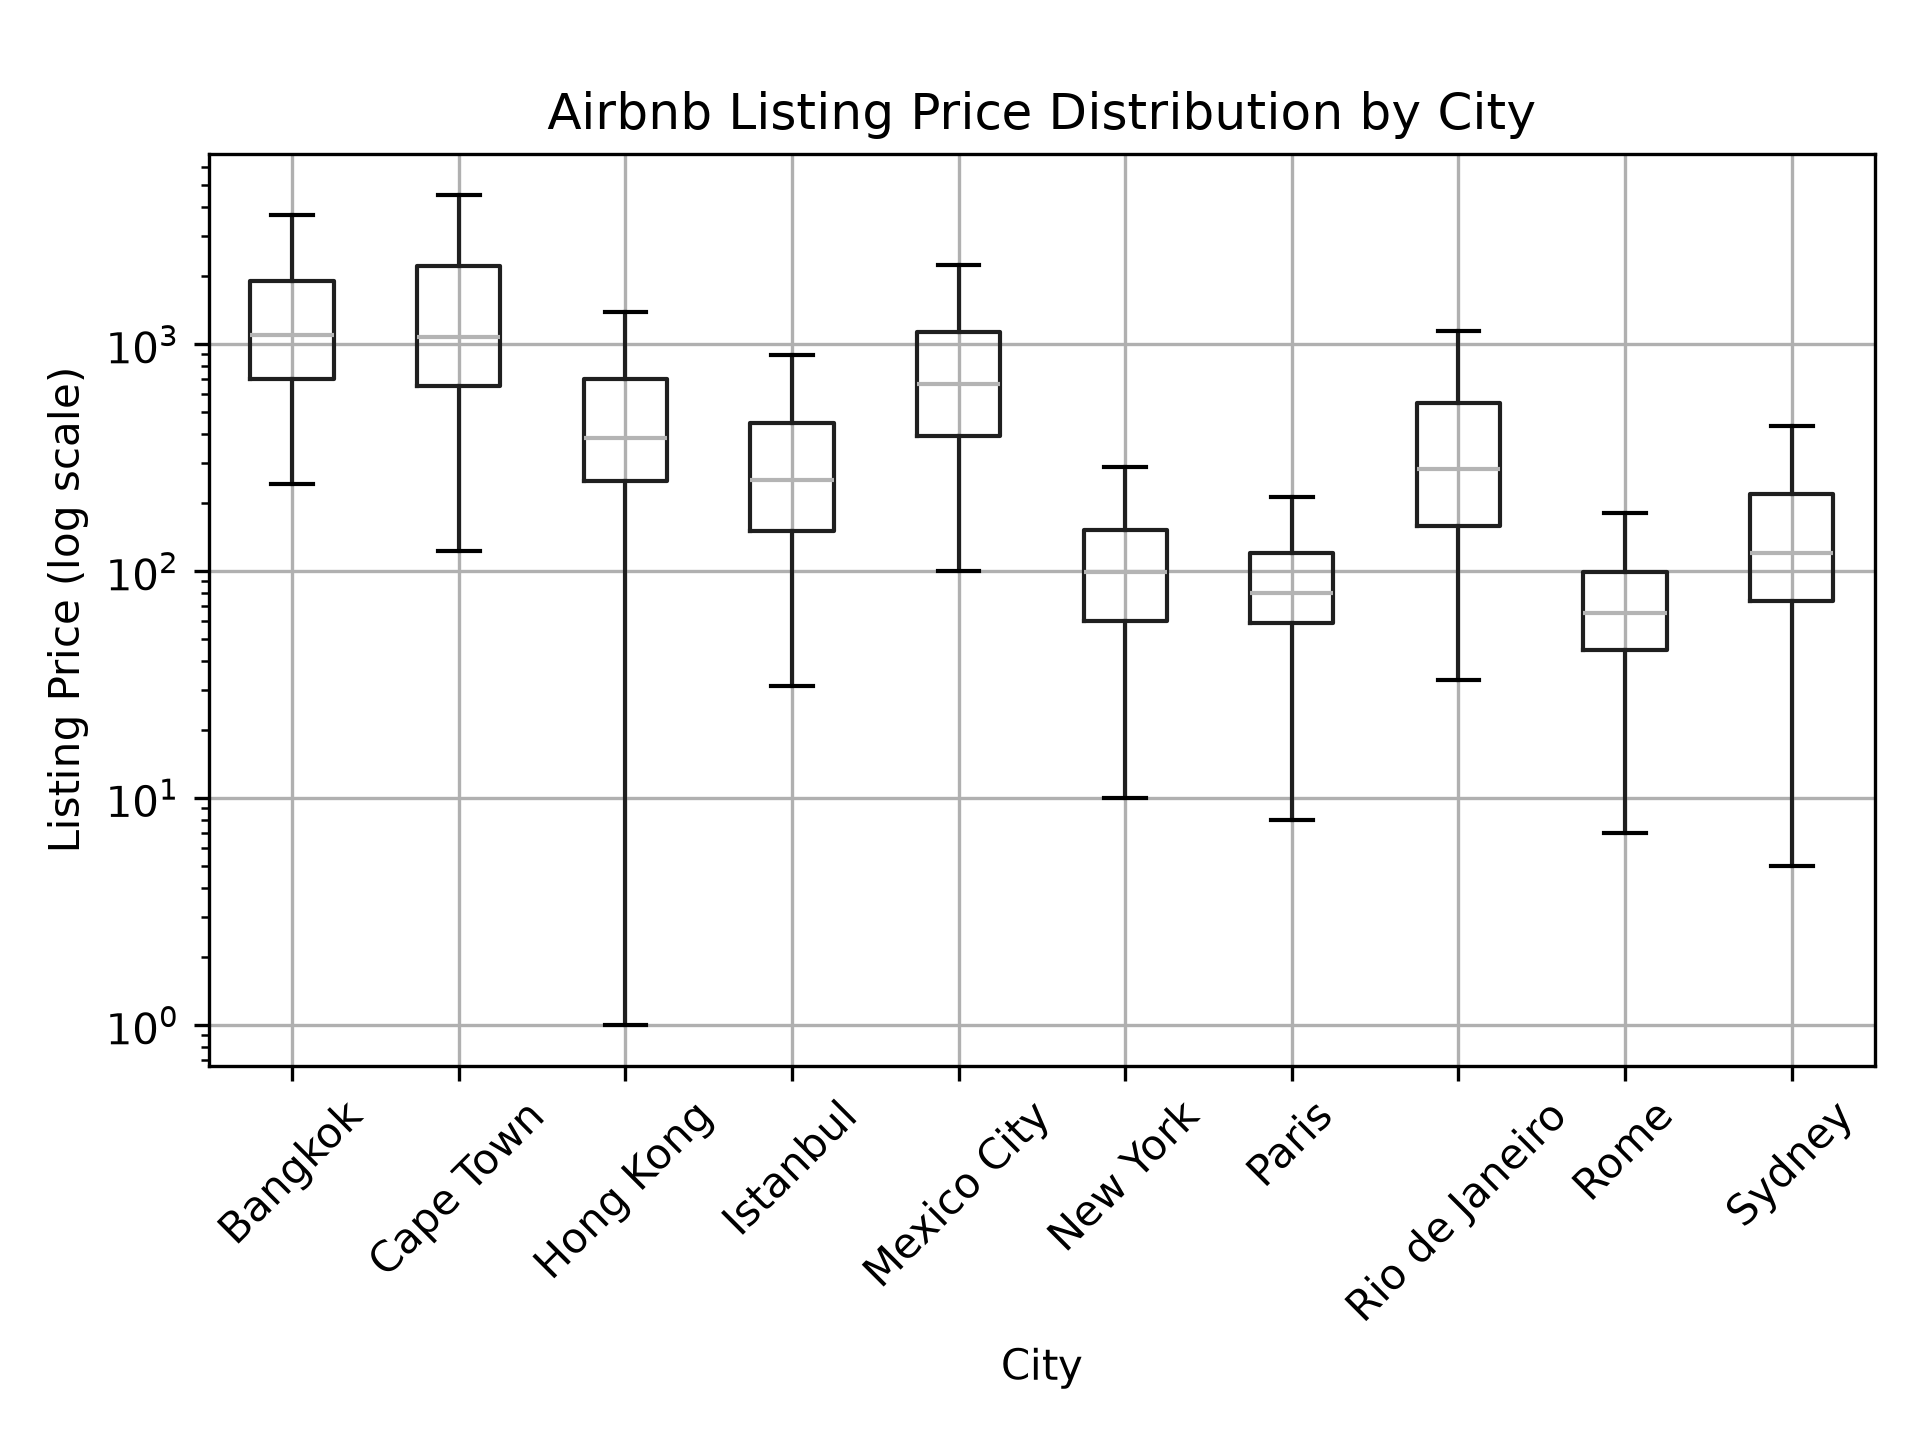

In [3]:
price_summary_path = REPORTS / "city_price_summary.csv"
if price_summary_path.exists():
    display(pd.read_csv(price_summary_path))
else:
    print("Missing:", price_summary_path)

price_plot = REPORTS / "figures" / "price_distribution_by_city.png"
if price_plot.exists():
    display(Image(filename=str(price_plot), width=1000))
else:
    print("Price distribution figure not found:", price_plot)

### Price distribution by room type

Room type can be an important determinant of advertised price. The following reports preserve the city-level and extended room-type summaries produced during exploratory analysis.

In [4]:
for filename in ["city_room_type_price_summary.csv",
                 "extended_city_room_type_price_summary.csv"]:
    path = REPORTS / filename
    print(f"\\n--- {filename} ---")
    if path.exists():
        display(pd.read_csv(path).head(30))
    else:
        print("Not found:", path)

\n--- city_room_type_price_summary.csv ---


,city,room_type,listing_count,median_price,mean_price,maximum_price
0,Bangkok,Entire place,10623,1192.0,2155.564059,300000
1,Bangkok,Hotel room,1019,1275.0,2092.803729,50000
2,Bangkok,Private room,6993,1000.0,2037.347204,300177
3,Bangkok,Shared room,725,450.0,1323.100690,100000
4,Cape Town,Entire place,14150,1287.5,2815.566855,180000
5,Cape Town,Hotel room,306,1350.5,2929.787582,45000
6,Cape Town,Private room,4503,622.0,1133.451255,140000
7,Cape Town,Shared room,127,282.0,499.291339,3120
8,Hong Kong,Entire place,2589,690.0,1016.570877,31000
9,Hong Kong,Hotel room,180,450.0,925.577778,10000


\n--- extended_city_room_type_price_summary.csv ---


,city,room_type,listing_count,median_price,mean_price,percentile_95,percentile_99,maximum_price
0,Bangkok,Entire place,10623,1192.0,2155.564059,5995.00,15971.36,300000
1,Bangkok,Hotel room,1019,1275.0,2092.803729,6229.10,10491.18,50000
2,Bangkok,Private room,6993,1000.0,2037.347204,4500.00,17123.16,300177
3,Bangkok,Shared room,725,450.0,1323.100690,3370.00,16368.00,100000
4,Cape Town,Entire place,14150,1287.5,2815.566855,8999.00,24653.00,180000
5,Cape Town,Hotel room,306,1350.5,2929.787582,9826.00,33912.30,45000
6,Cape Town,Private room,4503,622.0,1133.451255,2939.40,9795.80,140000
7,Cape Town,Shared room,127,282.0,499.291339,1500.00,2574.00,3120
8,Hong Kong,Entire place,2589,690.0,1016.570877,2517.40,9441.00,31000
9,Hong Kong,Hotel room,180,450.0,925.577778,2050.00,10000.00,10000


## 5. Price anomaly investigation

The anomaly investigation examined zero prices, unusually high prices and city-level extremes. Zero-price records were excluded from model training. High prices were not removed solely because they exceeded a statistical threshold: they may represent genuine premium listings, unusual data entries or both.

The reports below provide the audit trail for these decisions.

In [5]:
anomaly_files = [
    "zero_price_by_city.csv",
    "zero_price_records.csv",
    "city_price_outliers.csv",
    "extreme_price_summary.csv",
    "top_prices_by_city.csv",
    "highest_100_price_records.csv",
    "high_price_records_by_city.csv",
]
for filename in anomaly_files:
    path = REPORTS / filename
    print(f"\\n--- {filename} ---")
    if path.exists():
        display(pd.read_csv(path).head(15))
    else:
        print("Not found:", path)

\n--- zero_price_by_city.csv ---


,city,zero_price_count,total_listings,zero_price_percentage
0,Bangkok,1,19361,0.005165
1,Cape Town,0,19086,0.000000
2,Hong Kong,0,7087,0.000000
3,Istanbul,2,24519,0.008157
4,Mexico City,7,20065,0.034887
5,New York,28,37012,0.075651
6,Paris,62,64690,0.095842
7,Rio de Janeiro,7,26615,0.026301
8,Rome,6,27647,0.021702
9,Sydney,0,33630,0.000000


\n--- zero_price_records.csv ---


,listing_id,city,property_type,room_type,accommodates,bedrooms,minimum_nights,maximum_nights,price
0,44312919,Paris,Room in boutique hotel,Hotel room,0,NaN,1,1125,0
1,42830099,New York,Room in boutique hotel,Hotel room,0,NaN,30,365,0
2,43247472,New York,Room in boutique hotel,Hotel room,0,NaN,30,365,0
3,43205598,New York,Room in boutique hotel,Hotel room,0,NaN,1,365,0
4,44567521,New York,Room in boutique hotel,Hotel room,0,NaN,1,365,0
5,45985185,New York,Room in boutique hotel,Hotel room,0,NaN,1,365,0
6,46251446,New York,Room in boutique hotel,Hotel room,0,NaN,1,365,0
7,43012882,Paris,Room in hotel,Hotel room,0,NaN,1,365,0
8,43035744,Paris,Room in boutique hotel,Hotel room,0,NaN,1,365,0
9,43274767,Paris,Room in boutique hotel,Hotel room,0,NaN,1,365,0


\n--- city_price_outliers.csv ---


,city,Q1,Q3,IQR,lower_fence,upper_fence,total_outliers,high_price_outliers,outlier_percentage
0,Rio de Janeiro,157.0,550.0,393.0,-432.5,1139.5,2770,2770,10.410403
1,Cape Town,650.0,2200.0,1550.0,-1675.0,4525.0,1971,1971,10.326941
2,Sydney,74.0,219.0,145.0,-143.5,436.5,3328,3328,9.895926
3,Hong Kong,248.0,700.0,452.0,-430.0,1378.0,620,620,8.748413
4,Bangkok,700.0,1900.0,1200.0,-1100.0,3700.0,1680,1680,8.677686
5,Rome,45.0,99.0,54.0,-36.0,180.0,2232,2232,8.074961
6,Paris,59.0,120.0,61.0,-32.5,211.5,5164,5164,7.990345
7,Istanbul,150.0,449.0,299.0,-298.5,897.5,1917,1917,7.819064
8,Mexico City,392.0,1124.0,732.0,-706.0,2222.0,1497,1497,7.463356
9,New York,60.0,151.0,91.0,-76.5,287.5,2727,2727,7.373459


... (4 outputs left out)

\n--- highest_100_price_records.csv ---


,listing_id,name,city,property_type,room_type,accommodates,bedrooms,minimum_nights,maximum_nights,price
0,13879989,Temporary rentals for Brazilian Cup.,Rio de Janeiro,Shared room in house,Shared room,5,1.0,6,8,625216
1,47885441,Hotel Boutique Maison Salamanca,Mexico City,Room in boutique hotel,Private room,4,1.0,1,31,499000
2,23895520,Habitacion a 40min del centro historico,Mexico City,Private room in house,Private room,4,2.0,1,1125,350000
3,3410763,Amazing view and pool in center Bkk,Bangkok,Private room in apartment,Private room,2,1.0,1,1125,300177
4,13033135,Airport-MRT-ShowShopFood-FullFN,Bangkok,Private room in house,Private room,4,1.0,120,735,300000
5,12056763,Charoenkrung Road House/Office Rent,Bangkok,Entire house,Entire place,4,3.0,365,730,300000
6,29970931,Ã¥â€¦Â¬Ã¥Â¯â€œ,Bangkok,Entire apartment,Entire place,2,NaN,1,1125,231047
7,38733276,Room in the most exclusive area in Mexico City,Mexico City,Private room in apartment,Private room,1,1.0,1,7,206499
8,41578696,Ã¥Â¥Â¢Ã¥Â�Å½Ã§Â§Â�Ã¥Â®Â¶Ã¥Âºâ€žÃ¥â€ºÂ­Ã¯Â¼Å’Ã¤...,Bangkok,Entire villa,Entire place,10,5.0,1,1125,180124
9,36421447,Ellerman Villa One,Cape Town,Entire villa,Entire place,10,5.0,3,365,180000


\n--- high_price_records_by_city.csv ---


,listing_id,city,property_type,room_type,accommodates,bedrooms,minimum_nights,maximum_nights,price
0,3410763,Bangkok,Private room in apartment,Private room,2,1.0,1,1125,300177
1,13033135,Bangkok,Private room in house,Private room,4,1.0,120,735,300000
2,12056763,Bangkok,Entire house,Entire place,4,3.0,365,730,300000
3,29970931,Bangkok,Entire apartment,Entire place,2,NaN,1,1125,231047
4,41578696,Bangkok,Entire villa,Entire place,10,5.0,1,1125,180124
5,16045517,Bangkok,Entire apartment,Entire place,4,1.0,3,365,160000
6,31064616,Bangkok,Private room in apartment,Private room,2,1.0,1,1125,137031
7,20738147,Bangkok,Entire house,Entire place,16,2.0,1,1125,100000
8,10870677,Bangkok,Private room in house,Private room,6,1.0,1,1125,100000
9,15479247,Bangkok,Shared room in house,Shared room,5,1.0,1,1125,100000


## 6. Modelling dataset preparation

The target variable was `price`. The modelling dataset used the following features.

**Numerical features**
- `accommodates`
- `bedrooms`
- `bedrooms_missing`
- `minimum_nights`
- `maximum_nights`
- `amenities_count`
- `latitude`
- `longitude`

**Categorical features**
- `property_type`
- `room_type`
- `neighbourhood`
- `instant_bookable`

`listing_id` and `host_id` were retained for traceability but excluded from model features. Missing bedroom information was represented with a missingness indicator. Amenities were converted into a count. Numeric and categorical preprocessing was fitted within model pipelines to avoid fitting preprocessing transformations on the test data.

The modelling dataset excluded the 113 zero-price records. Each city was split into training and test data, approximately 80:20.

In [6]:
feature_path = REPORTS / "feature_definitions.json"
if feature_path.exists():
    with open(feature_path, "r", encoding="utf-8") as f:
        feature_definitions = json.load(f)
    print(json.dumps(feature_definitions, indent=2))
else:
    print("Feature definitions file not found.")

split_path = REPORTS / "city_train_test_summary.csv"
if split_path.exists():
    display(pd.read_csv(split_path))
else:
    print("Train/test summary not found.")

{
  "target": "price",
  "numeric_features": [
    "accommodates",
    "bedrooms",
    "bedrooms_missing",
    "minimum_nights",
    "maximum_nights",
    "amenities_count",
    "latitude",
    "longitude"
  ],
  "categorical_features": [
    "property_type",
    "room_type",
    "neighbourhood",
    "instant_bookable"
  ],
  "identifier_columns": [
    "listing_id",
    "host_id"
  ],
  "excluded_from_model": [
    "listing_id",
    "host_id",
    "city",
    "name",
    "amenities",
    "review_scores_rating",
    "review_scores_accuracy",
    "review_scores_cleanliness",
    "review_scores_checkin",
    "review_scores_communication",
    "review_scores_location",
    "review_scores_value"
  ],
  "target_definition": "Advertised listing price in the city's local currency.",
  "prediction_scenario": "Estimate listing price using property characteristics and location information.",
  "currency_strategy": "Separate models for each city to avoid mixing currencies.",
  "zero_price_policy"

,city,total_listings,training_listings,testing_listings
0,Bangkok,19360,15488,3872
1,Cape Town,19086,15268,3818
2,Hong Kong,7087,5669,1418
3,Istanbul,24517,19613,4904
4,Mexico City,20058,16046,4012
5,New York,36984,29587,7397
6,Paris,64628,51702,12926
7,Rio de Janeiro,26608,21286,5322
8,Rome,27641,22112,5529
9,Sydney,33630,26904,6726


## 7. Candidate model comparison

The modelling workflow compared a median baseline with several regression algorithms:

- Linear Regression
- Random Forest Regression
- Gradient Boosting Regression
- Histogram-based Gradient Boosting Regression

Both the original target and a logarithmically transformed target were investigated. Predictions from log-target models were transformed back to the original local-currency scale before evaluation.

The initial model-comparison outputs are retained below as development evidence. The later validation stage, rather than the initial test comparison, was used to select the final configurations.

In [7]:
evaluation_dir = REPORTS / "model_evaluation"
for filename in ["model_comparison_all_cities.csv", "best_models_by_city.csv"]:
    path = evaluation_dir / filename
    print(f"\\n--- {filename} ---")
    if path.exists():
        display(pd.read_csv(path))
    else:
        print("Not found:", path)

\n--- model_comparison_all_cities.csv ---


,city,model,target_transform,MAE,RMSE,R2
0,bangkok,Random Forest,Log,1077.229313,7741.809062,0.053272
1,bangkok,HistGradientBoosting,Log,1178.355626,7804.608666,0.037850
2,bangkok,Random Forest,Original,1378.104893,7915.051963,0.010427
3,bangkok,Median Baseline,Original,1452.815083,8025.958474,-0.017499
4,bangkok,HistGradientBoosting,Original,1486.244845,7824.127123,0.033032
...,...,...,...,...,...,...
65,sydney,HistGradientBoosting,Original,106.708954,480.763747,0.208004
66,sydney,Gradient Boosting,Original,109.115380,491.101899,0.173576
67,sydney,Random Forest,Original,109.124480,494.318931,0.162713
68,sydney,Linear Regression,Original,126.320832,500.275529,0.142413


\n--- best_models_by_city.csv ---


,city,model,target_transform,MAE,RMSE,R2,model_file
0,bangkok,Random Forest,Log,1077.229313,7741.809062,0.053272,bangkok_best_model.joblib
1,cape_town,Random Forest,Log,994.433238,4025.348027,0.438135,cape_town_best_model.joblib
2,hong_kong,Random Forest,Log,380.964001,2535.606404,0.046456,hong_kong_best_model.joblib
3,istanbul,HistGradientBoosting,Log,400.034893,4836.356671,0.007967,istanbul_best_model.joblib
4,mexico_city,HistGradientBoosting,Log,554.071046,3366.286892,0.066276,mexico_city_best_model.joblib
5,new_york,Random Forest,Log,51.984043,214.048752,0.211326,new_york_best_model.joblib
6,paris,Random Forest,Log,39.563976,201.946819,0.145807,paris_best_model.joblib
7,rio_de_janeiro,HistGradientBoosting,Log,520.775260,4288.857264,0.020798,rio_de_janeiro_best_model.joblib
8,rome,Random Forest,Log,44.949788,261.287835,0.225812,rome_best_model.joblib
9,sydney,HistGradientBoosting,Log,90.618169,487.346182,0.186168,sydney_best_model.joblib


## 8. Validation and model selection

Candidate configurations were compared on validation data drawn from the training portion. Validation MAE was the primary selection metric, with RMSE used as a tiebreaker.

A grouped split by `host_id` was also used as a diagnostic of generalisation to unseen hosts. This grouped evaluation is additional evidence; it was not used as the primary configuration-selection result.

All ten selected configurations used a log-transformed target. Random Forest was selected for eight cities, while Histogram-based Gradient Boosting was selected for Paris and Sydney.

In [8]:
validation_dir = REPORTS / "model_validation"
for filename in ["selected_models_by_city.csv",
                 "validation_model_comparison.csv",
                 "group_validation_results.csv"]:
    path = validation_dir / filename
    print(f"\\n--- {filename} ---")
    if path.exists():
        display(pd.read_csv(path))
    else:
        print("Not found:", path)

\n--- selected_models_by_city.csv ---


,city,model,configuration,target_transform,MAE,RMSE,R2
0,bangkok,Random Forest,Configuration 1,log,1149.240556,7277.652183,0.052259
1,cape_town,Random Forest,Configuration 1,log,1114.219144,5665.173323,0.348656
2,hong_kong,Random Forest,Configuration 1,log,422.216101,1912.810695,0.078666
3,istanbul,Random Forest,Configuration 1,log,284.756893,2393.902439,0.020186
4,mexico_city,Random Forest,Configuration 1,log,462.538861,2045.250859,0.114643
5,new_york,Random Forest,Configuration 1,log,53.699628,227.636246,0.206488
6,paris,HistGradientBoosting,Configuration 2,log,39.888017,205.608585,0.139292
7,rio_de_janeiro,Random Forest,Configuration 1,log,538.448466,4764.333228,0.037951
8,rome,Random Forest,Configuration 2,log,44.553545,268.375324,0.073873
9,sydney,HistGradientBoosting,Configuration 2,log,93.564221,462.097892,0.222495


\n--- validation_model_comparison.csv ---


,city,model,configuration,target_transform,MAE,RMSE,R2
0,bangkok,Random Forest,Configuration 1,log,1149.240556,7277.652183,0.052259
1,bangkok,Random Forest,Configuration 2,log,1166.375472,7299.820470,0.046476
2,bangkok,HistGradientBoosting,Configuration 2,log,1200.053217,7311.742697,0.043359
3,bangkok,HistGradientBoosting,Configuration 1,log,1210.029577,7326.158372,0.039583
4,bangkok,Gradient Boosting,Configuration 2,log,1268.093253,7359.171782,0.030908
...,...,...,...,...,...,...,...
145,sydney,Gradient Boosting,Configuration 2,original,111.996154,465.065974,0.212475
146,sydney,Gradient Boosting,Configuration 1,original,113.191001,464.116470,0.215688
147,sydney,Linear Regression,Configuration 1,original,129.216489,471.129543,0.191806
148,sydney,Median Baseline,Default,original,153.871399,535.042366,-0.042345


\n--- group_validation_results.csv ---


,city,status,selected_model,configuration,target_transform,training_rows,validation_rows,training_hosts,validation_hosts,MAE,RMSE,R2
0,bangkok,Completed,Random Forest,Configuration 1,log,12383,3105,5713,1429,1415.136988,7397.219232,0.056127
1,cape_town,Completed,Random Forest,Configuration 1,log,12008,3260,7500,1875,973.819999,3720.284249,0.430204
2,hong_kong,Completed,Random Forest,Configuration 1,log,4707,962,1424,357,527.758915,2533.433772,0.014632
3,istanbul,Completed,Random Forest,Configuration 1,log,15509,4104,9129,2283,262.896305,1033.523338,0.048525
4,mexico_city,Completed,Random Forest,Configuration 1,log,12676,3370,7809,1953,649.088856,8822.525425,0.009181
5,new_york,Completed,Random Forest,Configuration 1,log,23702,5885,17715,4429,57.397503,201.991215,0.150880
6,paris,Completed,HistGradientBoosting,Configuration 2,log,41312,10390,33742,8436,42.863007,256.237026,0.105589
7,rio_de_janeiro,Completed,Random Forest,Configuration 1,log,17003,4283,11580,2895,782.315861,10780.733318,0.003459
8,rome,Completed,Random Forest,Configuration 2,log,17583,4529,10020,2506,52.323572,314.955522,0.040540
9,sydney,Completed,HistGradientBoosting,Configuration 2,log,21512,5392,16456,4115,87.412977,326.123324,0.405867


## 9. Final model training and independent testing

After model selection, the selected configurations were fitted on each city's full training dataset and evaluated on the untouched test dataset.

The table below reports the final independent test results. MAE and RMSE are expressed in each city's local currency and should not be compared directly across cities.

| City | Final model | Test MAE | Test RMSE | Test R² | Baseline MAE |
|---|---|---:|---:|---:|---:|
| Bangkok | Random Forest | 1,077.17 | 7,742.07 | 0.053 | 1,452.82 |
| Cape Town | Random Forest | 992.73 | 4,017.22 | 0.440 | 1,683.19 |
| Hong Kong | Random Forest | 380.70 | 2,535.77 | 0.046 | 515.61 |
| Istanbul | Random Forest | 392.81 | 4,840.00 | 0.006 | 462.65 |
| Mexico City | Random Forest | 535.56 | 3,326.85 | 0.088 | 735.52 |
| New York | Random Forest | 51.97 | 214.02 | 0.212 | 80.17 |
| Paris | Histogram-based Gradient Boosting | 39.66 | 203.92 | 0.129 | 55.86 |
| Rio de Janeiro | Random Forest | 517.63 | 4,276.62 | 0.026 | 628.19 |
| Rome | Random Forest | 45.85 | 280.04 | 0.111 | 57.02 |
| Sydney | Histogram-based Gradient Boosting | 90.52 | 486.62 | 0.189 | 149.48 |

All ten models achieved lower MAE than their corresponding median baseline. Cape Town had the highest test R² (approximately 0.440). Several cities had low R², showing that the available features explain only a limited share of price variation in those markets.

In [9]:
final_test_path = REPORTS / "final_test" / "final_test_model_comparison.csv"
if final_test_path.exists():
    print("Saved final-test comparison:")
    display(pd.read_csv(final_test_path))
else:
    print("Final test comparison report not found:", final_test_path)

Saved final-test comparison:


,city,model,configuration,target_transform,training_rows,testing_rows,test_MAE,test_RMSE,test_R2,baseline_MAE,baseline_RMSE,baseline_R2,MAE_improvement_percent,negative_predictions_clipped
0,bangkok,Random Forest,Configuration 1,log,15488,3872,1077.169462,7742.072812,0.053207,1452.815083,8025.958474,-0.017499,25.856396,0
1,cape_town,Random Forest,Configuration 1,log,15268,3818,992.724663,4017.218506,0.440402,1683.186747,5511.199152,-0.053215,41.021122,0
2,hong_kong,Random Forest,Configuration 1,log,5669,1418,380.700967,2535.768666,0.046334,515.608604,2623.628308,-0.020897,26.164737,0
3,istanbul,Random Forest,Configuration 1,log,19613,4904,392.809080,4839.995382,0.006473,462.646003,4869.288618,-0.005589,15.095110,0
4,mexico_city,Random Forest,Configuration 1,log,16046,4012,535.554701,3326.852801,0.088024,735.524177,3514.553551,-0.017786,27.187342,0
5,new_york,Random Forest,Configuration 1,log,29587,7397,51.972934,214.014559,0.211578,80.166689,244.792083,-0.031494,35.168915,0
6,paris,HistGradientBoosting,Configuration 2,log,51702,12926,39.663380,203.923134,0.129006,55.860668,220.935314,-0.022380,28.995873,0
7,rio_de_janeiro,Random Forest,Configuration 1,log,21286,5322,517.626719,4276.616399,0.026379,628.184517,4364.003542,-0.013816,17.599574,0
8,rome,Random Forest,Configuration 2,log,22112,5529,45.854492,280.043622,0.110678,57.014650,299.168679,-0.014939,19.574193,0
9,sydney,HistGradientBoosting,Configuration 2,log,26904,6726,90.517709,486.618814,0.188595,149.475766,550.017241,-0.036603,39.443221,0


## 10. Error analysis and model interpretation

The completed error analysis examined residual distributions, residuals against predictions, actual-versus-predicted values, errors by actual-price quartile and permutation feature importance.

Main findings:

- All ten models had positive mean residuals, indicating average underprediction under the residual convention used in the report (`actual - predicted`).
- Models generally overestimated the lowest price quartile and underestimated the highest price quartile.
- Absolute errors were substantially larger in the highest price quartile.
- A small number of extreme observations contributed disproportionately to RMSE in some cities.
- Bedrooms, accommodation capacity, geographical coordinates, property type and room type were frequently influential.

Permutation importance measures predictive contribution, not causation. Correlated features can share or obscure importance.

In [10]:
error_dir = REPORTS / "error_analysis"
for filename in ["error_analysis_summary.csv",
                 "error_by_price_range.csv",
                 "feature_importance_by_city.csv",
                 "largest_prediction_errors.csv"]:
    path = error_dir / filename
    print(f"\\n--- {filename} ---")
    if path.exists():
        display(pd.read_csv(path).head(30))
    else:
        print("Not found:", path)

\n--- error_analysis_summary.csv ---


,city,test_records,MAE,RMSE,R2,mean_error,median_absolute_error,90th_percentile_absolute_error,95th_percentile_absolute_error,maximum_absolute_error
0,bangkok,3872,1077.169462,7742.072812,0.053207,602.032486,307.035758,1520.583420,2448.073262,298904.251883
1,cape_town,3818,992.724663,4017.218506,0.440402,374.678639,291.159314,1789.394426,3217.793746,111975.109713
2,hong_kong,1418,380.700967,2535.768666,0.046334,201.508763,88.080702,527.173908,870.225155,82991.945756
3,istanbul,4904,392.809080,4839.995382,0.006473,270.629340,81.223100,368.194448,647.106394,179376.675232
4,mexico_city,4012,535.554701,3326.852801,0.088024,274.901432,161.721600,827.700839,1516.164323,157772.175218
5,new_york,7397,51.972934,214.014559,0.211578,19.407840,21.573472,95.089711,148.020010,9891.670027
6,paris,12926,39.663380,203.923134,0.129006,14.482490,18.118212,70.678744,116.220258,11271.249242
7,rio_de_janeiro,5322,517.626719,4276.616399,0.026379,343.414871,104.269669,698.241925,1324.295748,128879.941259
8,rome,5529,45.854492,280.043622,0.110678,22.084150,16.737432,71.597463,128.472798,9946.228177
9,sydney,6726,90.517709,486.618814,0.188595,37.458436,30.550451,170.683284,279.114949,28536.332103


\n--- error_by_price_range.csv ---


,price_range,listing_count,mean_actual_price,mean_predicted_price,MAE,median_absolute_error,city
0,"(240.999, 700.0]",1031,529.635306,849.730897,324.419285,237.760910,bangkok
1,"(700.0, 1100.0]",941,901.412327,1102.906842,273.784399,162.162600,bangkok
2,"(1100.0, 1948.5]",932,1442.139485,1443.151779,403.389301,286.234518,bangkok
3,"(1948.5, 300000.0]",968,5781.310950,2835.403782,3308.609426,1041.508204,bangkok
4,"(128.999, 627.0]",956,443.623431,649.634575,224.347652,154.549776,cape_town
5,"(627.0, 1050.0]",962,828.905405,968.589583,277.165633,166.614656,cape_town
6,"(1050.0, 2137.0]",945,1508.859259,1537.044201,512.675456,378.680048,cape_town
7,"(2137.0, 136500.0]",955,6494.272251,4621.517650,2957.732736,1247.195434,cape_town
8,"(77.999, 248.25]",355,183.569014,256.951489,82.637967,48.195352,hong_kong
9,"(248.25, 390.0]",357,306.885154,385.911346,109.963948,64.007757,hong_kong


\n--- feature_importance_by_city.csv ---


,feature,importance_mean,importance_std,city
0,bedrooms,230.893993,15.106131,bangkok
1,latitude,156.876617,2.910680,bangkok
2,longitude,149.222606,7.779820,bangkok
3,accommodates,136.175714,24.316466,bangkok
4,property_type,108.734957,11.951444,bangkok
5,amenities_count,93.567012,11.793196,bangkok
6,instant_bookable,58.343680,7.086406,bangkok
7,room_type,46.605847,1.716427,bangkok
8,neighbourhood,45.968623,6.367898,bangkok
9,minimum_nights,43.517661,3.720774,bangkok


\n--- largest_prediction_errors.csv ---


,actual_price,predicted_price,residual,absolute_error,listing_id,host_id,city
0,300000,1095.748117,298904.251883,298904.251883,13033135,34158729,bangkok
1,231047,1161.724815,229885.275185,229885.275185,29970931,116524834,bangkok
2,160000,1114.620611,158885.379389,158885.379389,16045517,94426146,bangkok
3,137031,1144.240575,135886.759425,135886.759425,31064616,20904996,bangkok
4,99000,1446.623823,97553.376177,97553.376177,37227373,172167918,bangkok
5,65000,2335.234238,62664.765762,62664.765762,7625178,39999413,bangkok
6,60000,2348.989734,57651.010266,57651.010266,39929656,156853276,bangkok
7,50000,1170.182105,48829.817895,48829.817895,39875920,307084105,bangkok
8,50000,3105.109030,46894.890970,46894.890970,45726807,337003018,bangkok
9,46444,1074.673828,45369.326172,45369.326172,39097678,134586801,bangkok


### City-level diagnostic plots

The following cell displays the existing actual-versus-predicted and feature-importance plots for each city. Residual plots and residual distributions are also available in `reports/error_analysis/figures/`.

Bangkok — Actual vs Predicted


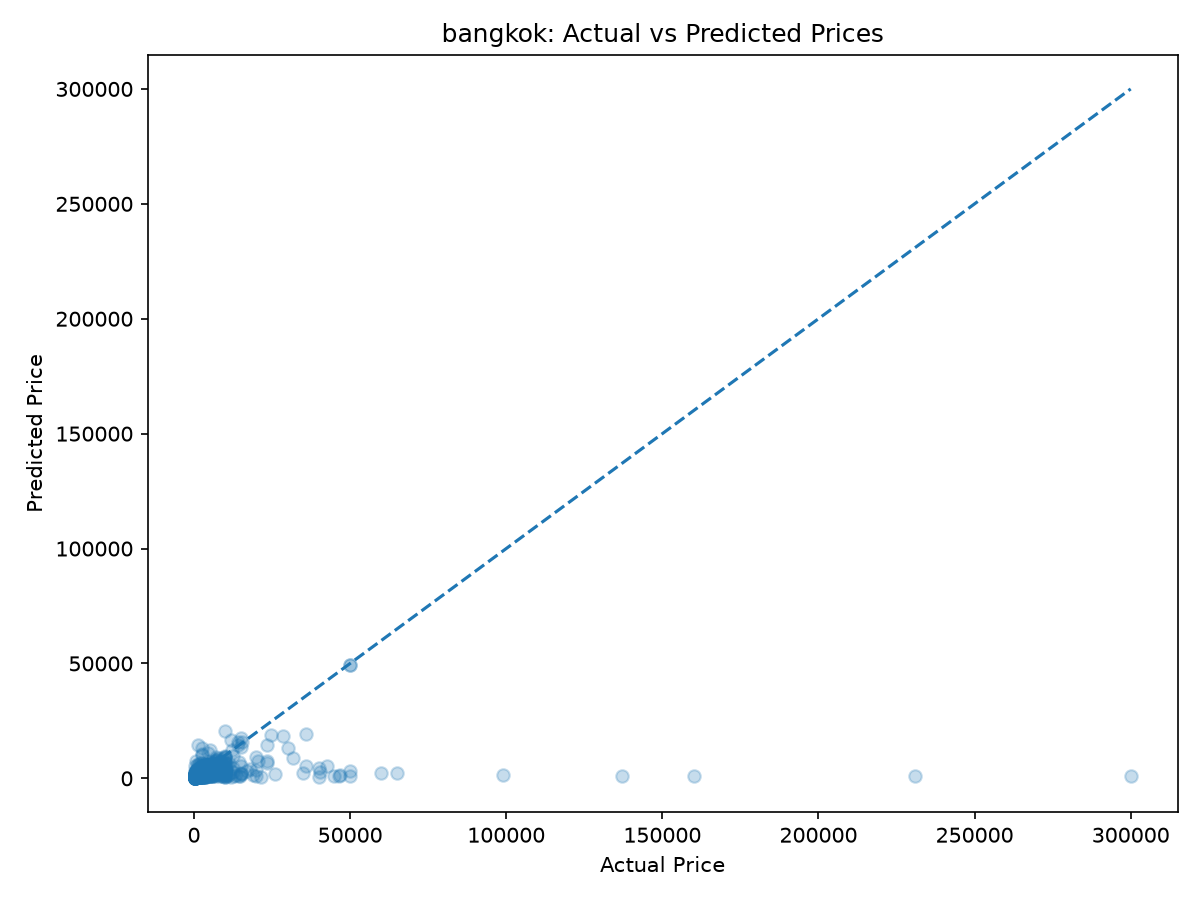

Bangkok — Permutation Feature Importance


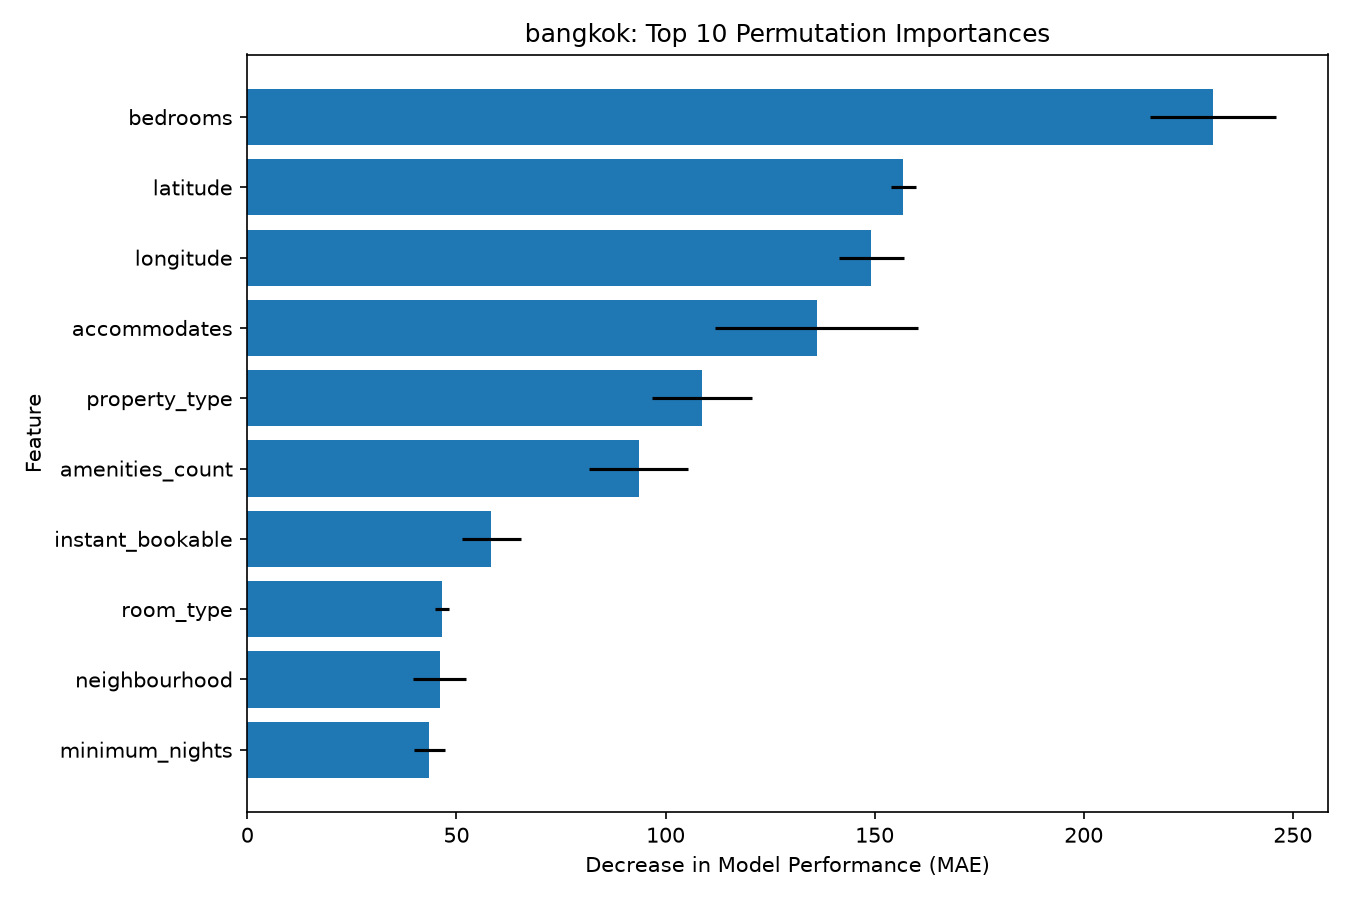

Cape Town — Actual vs Predicted


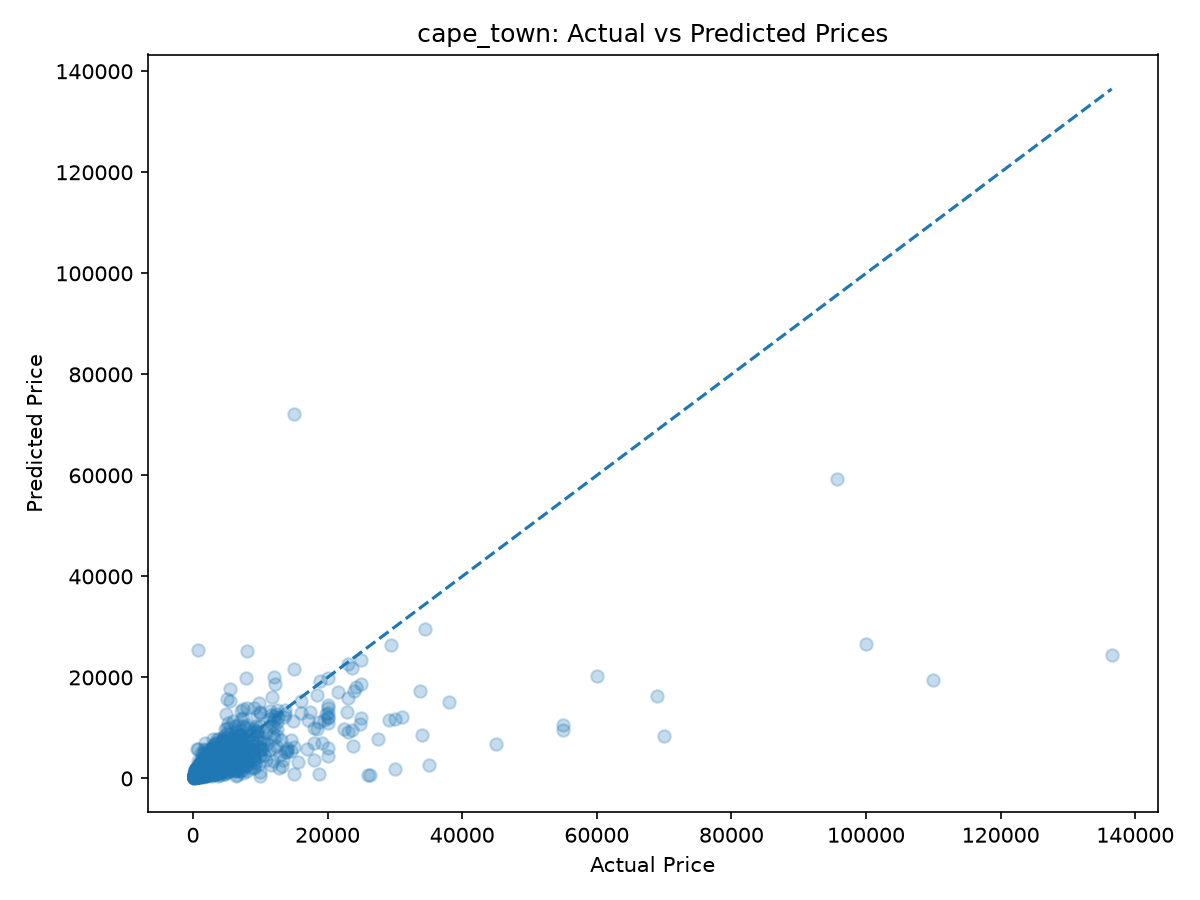

Cape Town — Permutation Feature Importance


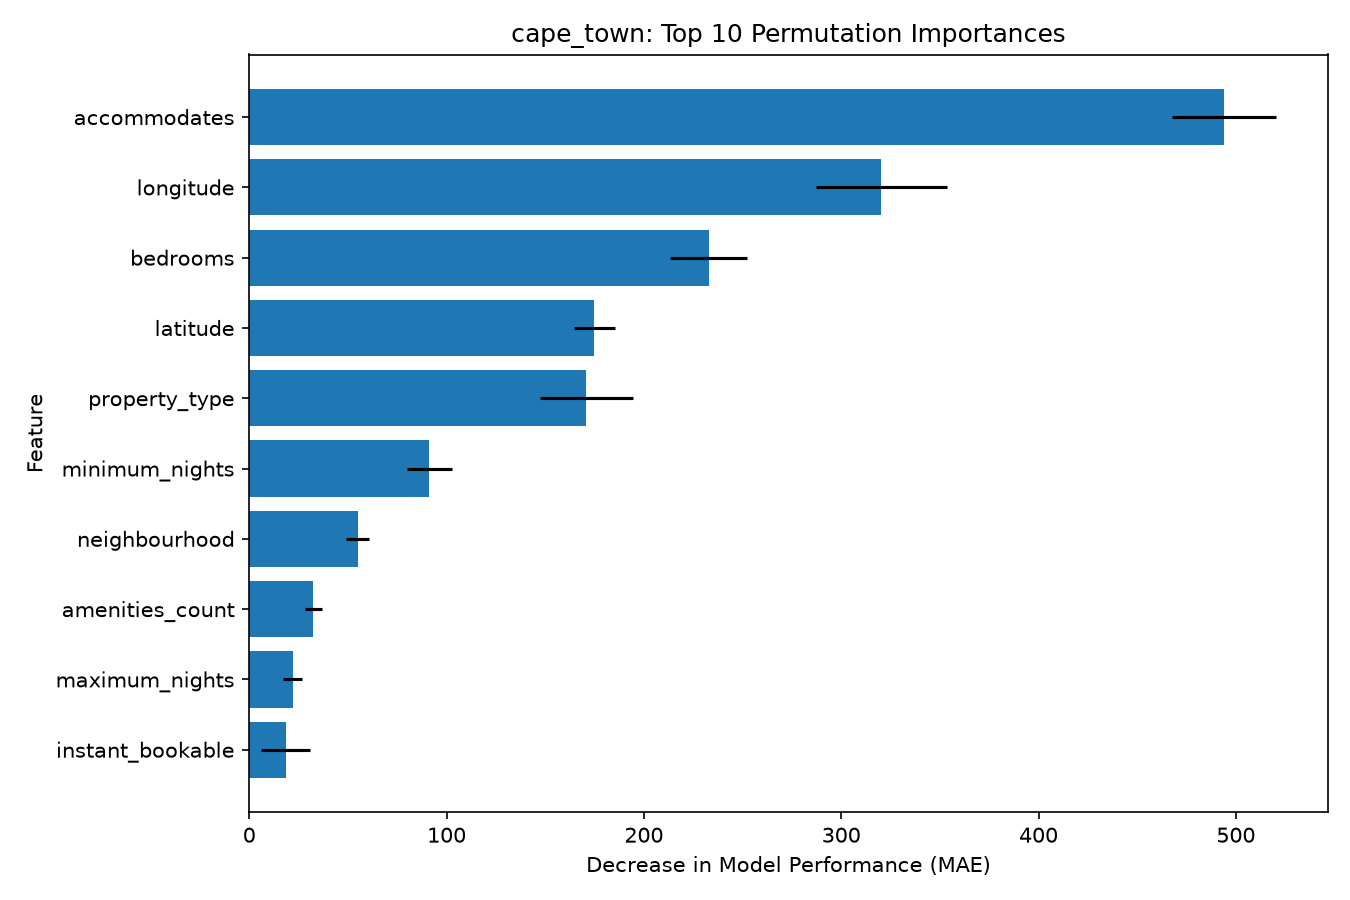

Hong Kong — Actual vs Predicted


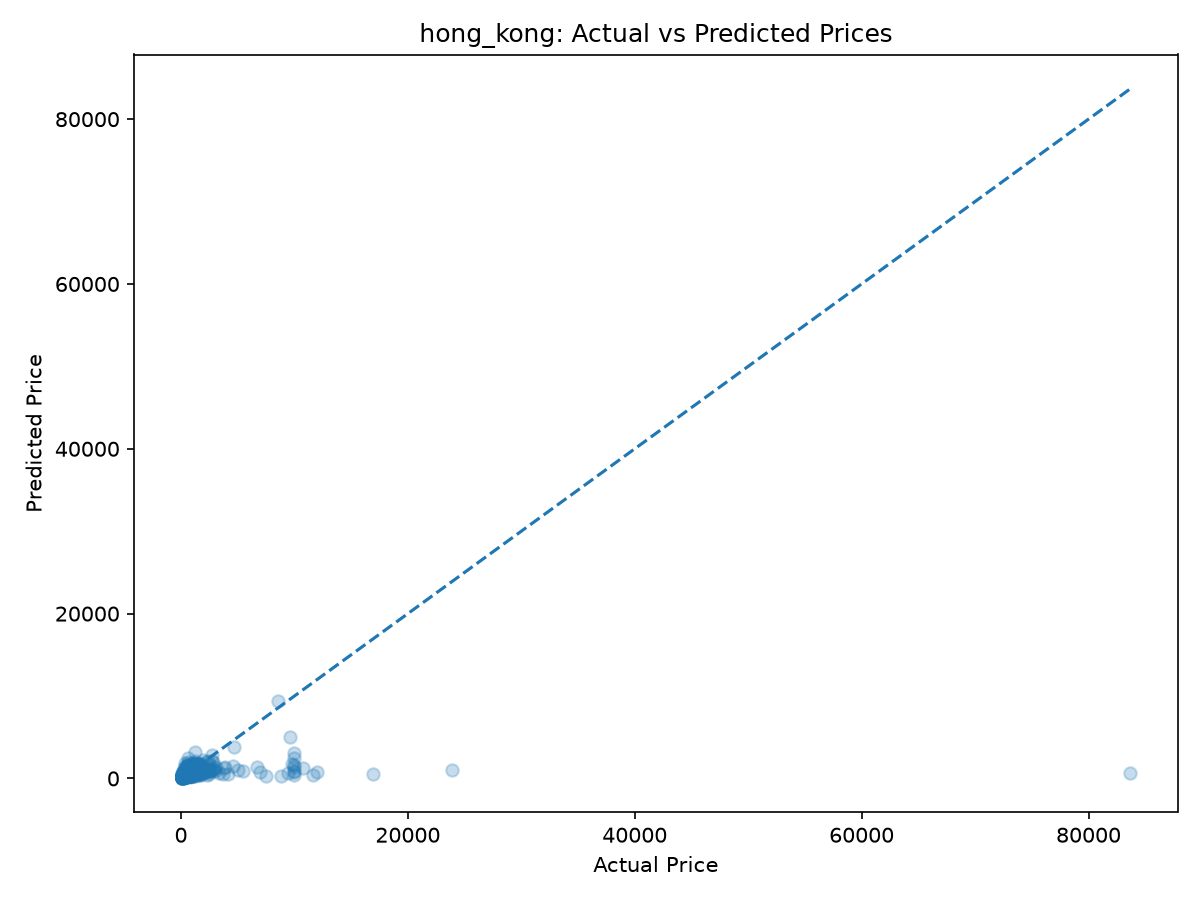

Hong Kong — Permutation Feature Importance


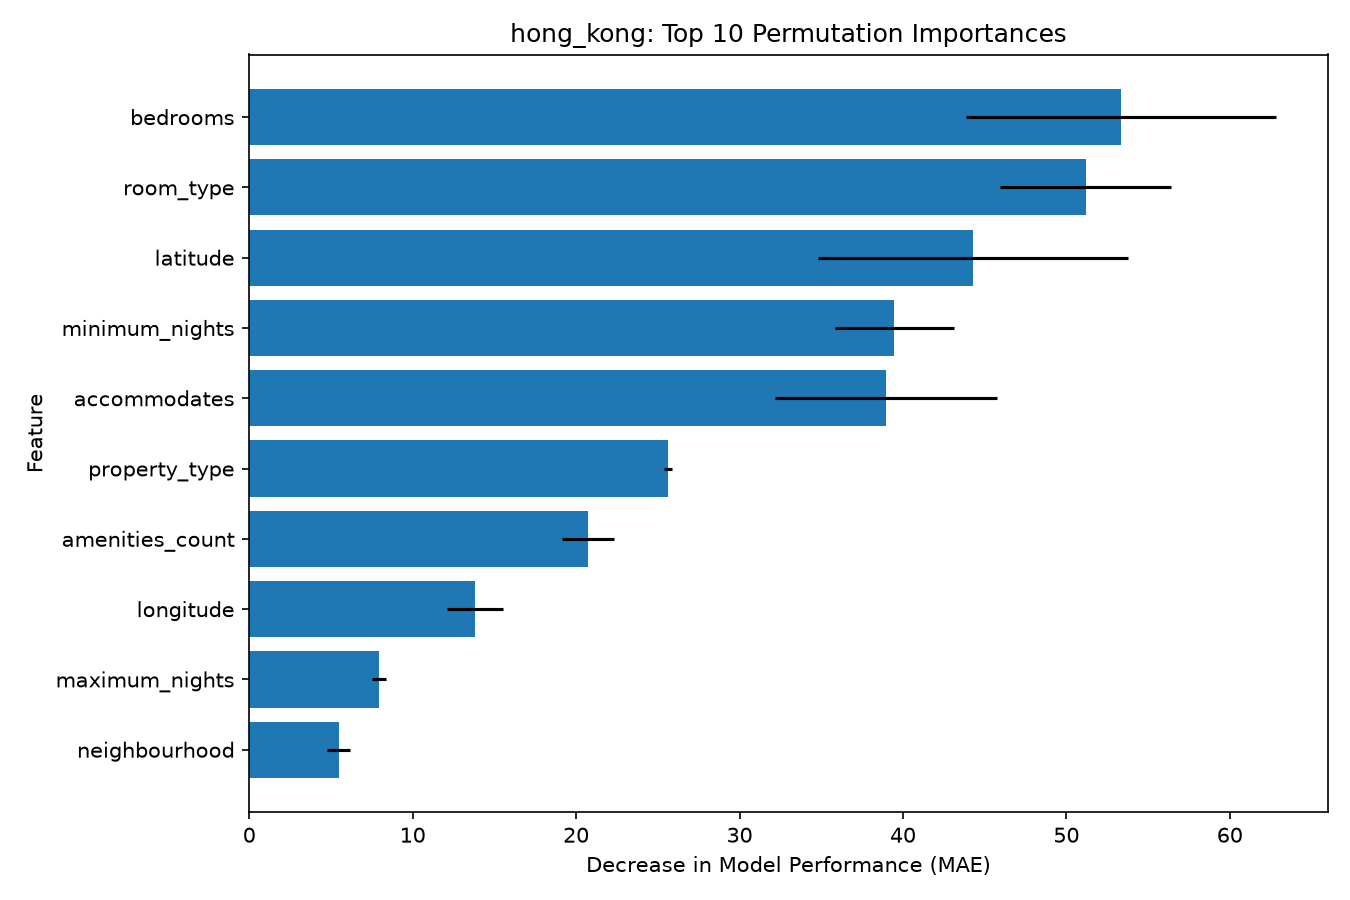

Istanbul — Actual vs Predicted


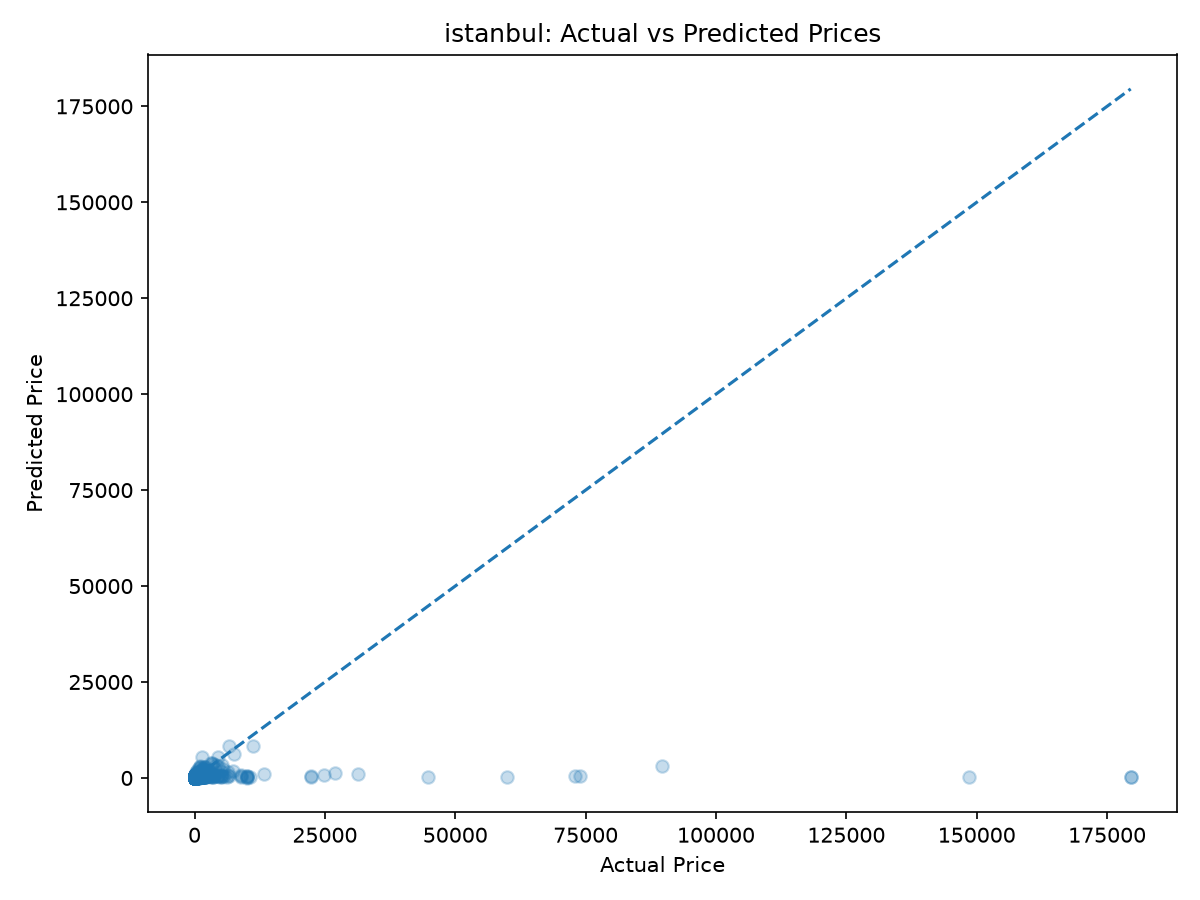

Istanbul — Permutation Feature Importance


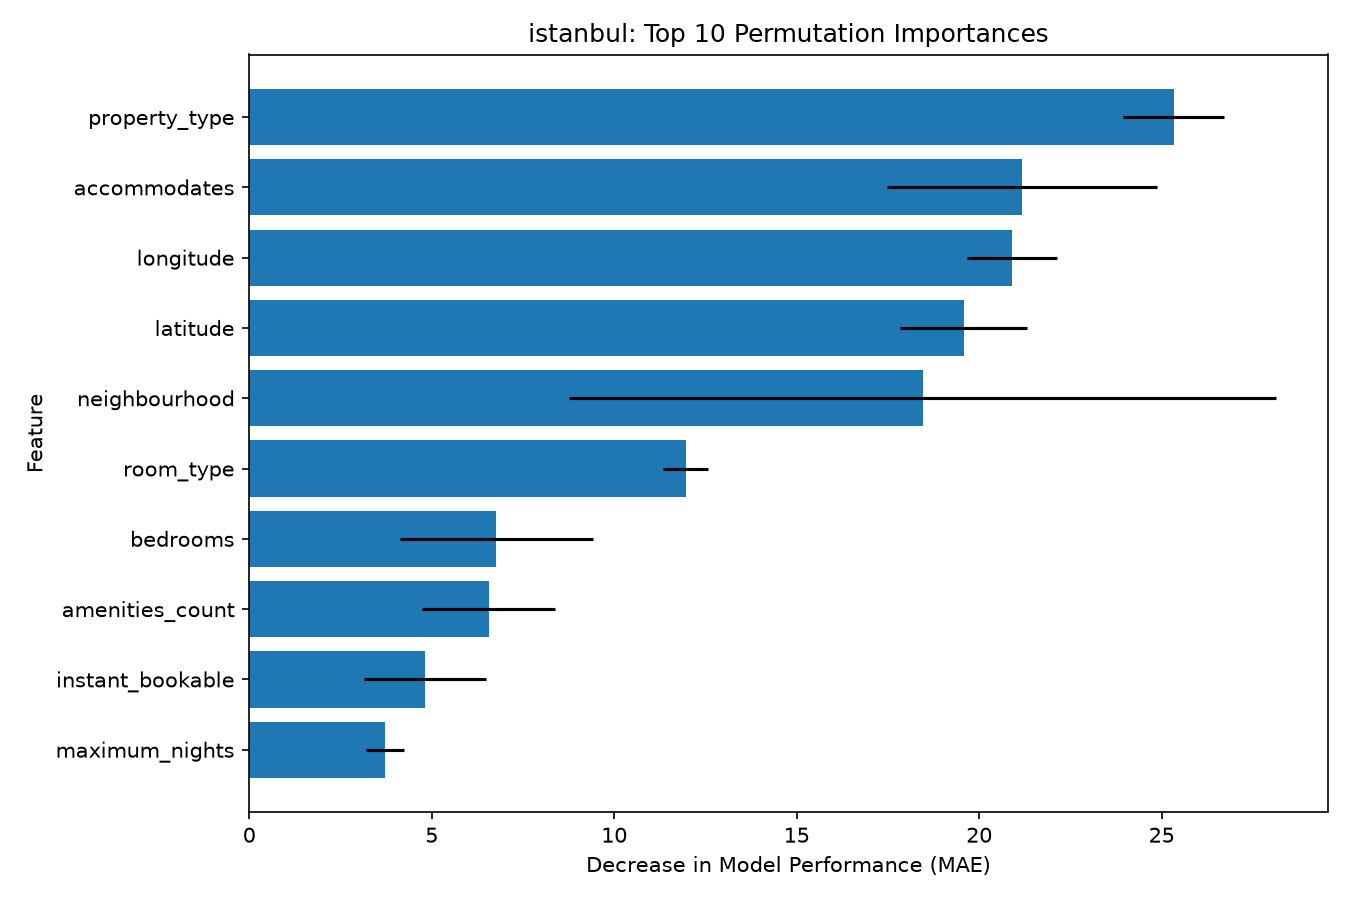

Mexico City — Actual vs Predicted


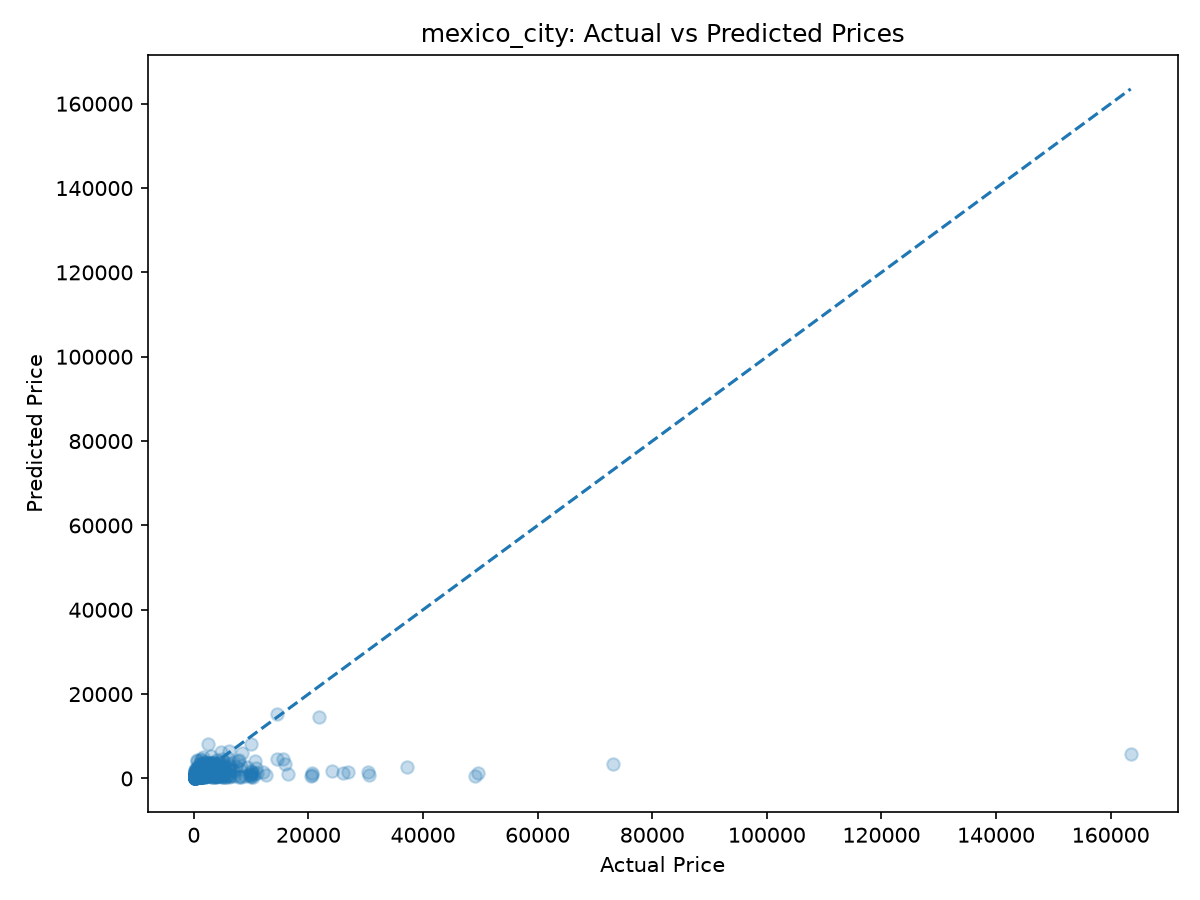

Mexico City — Permutation Feature Importance


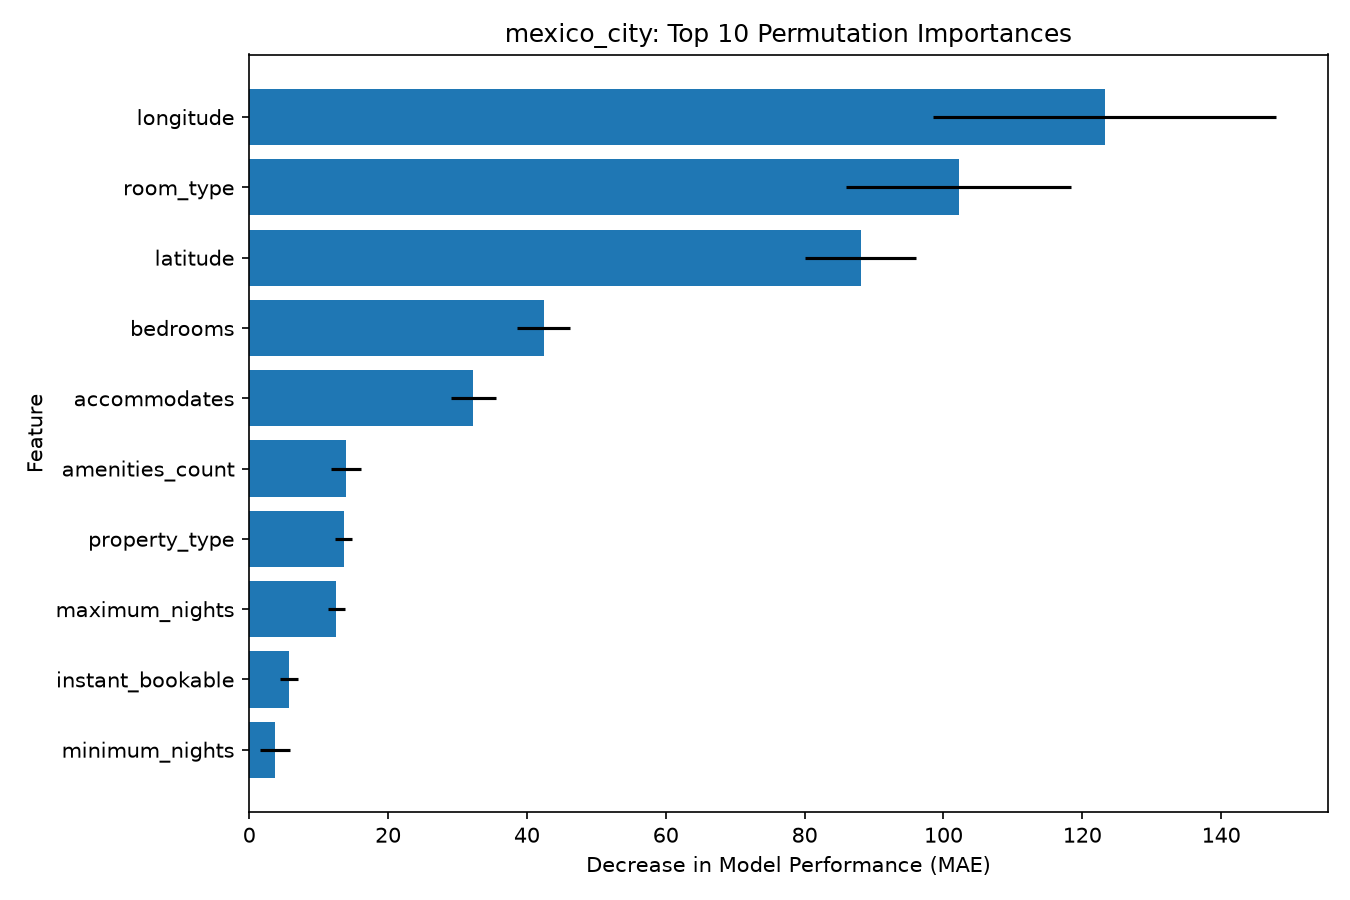

New York — Actual vs Predicted


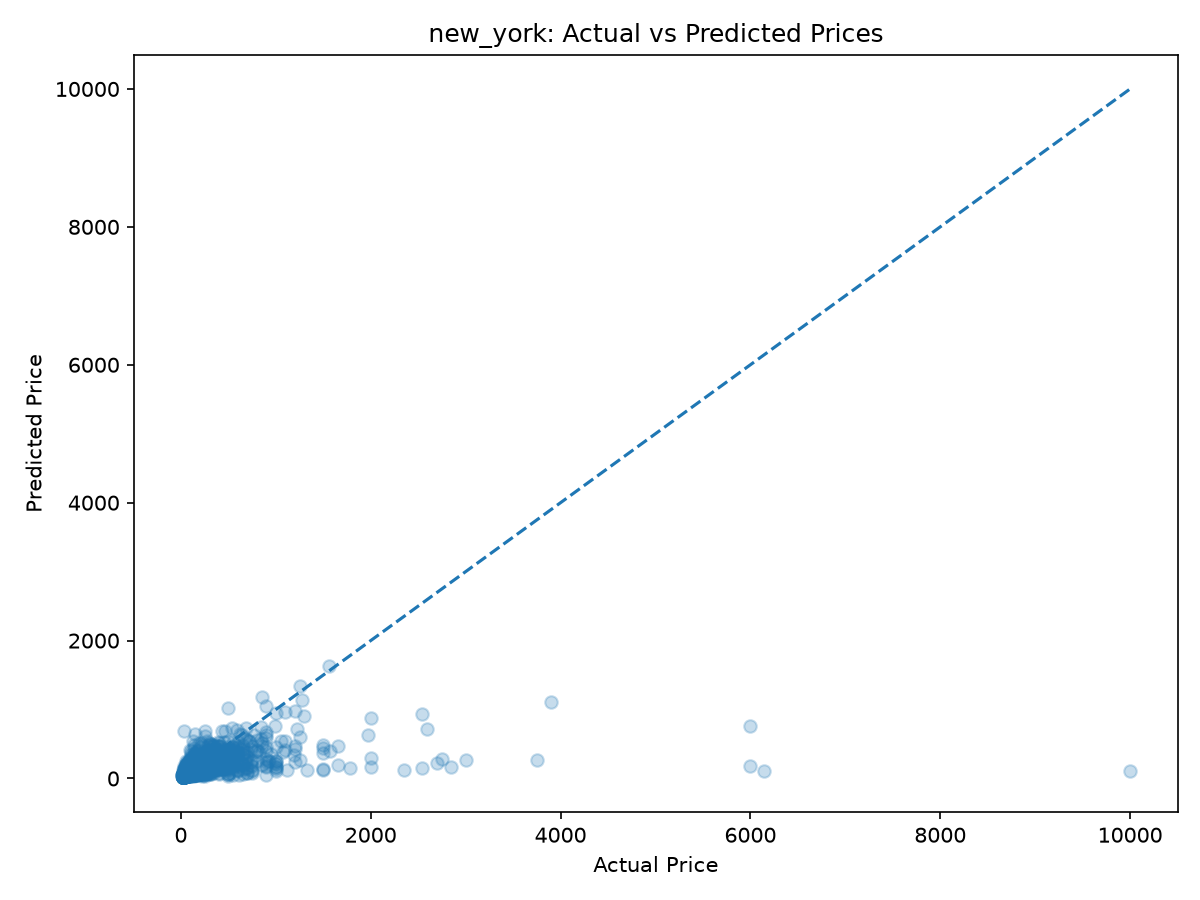

New York — Permutation Feature Importance


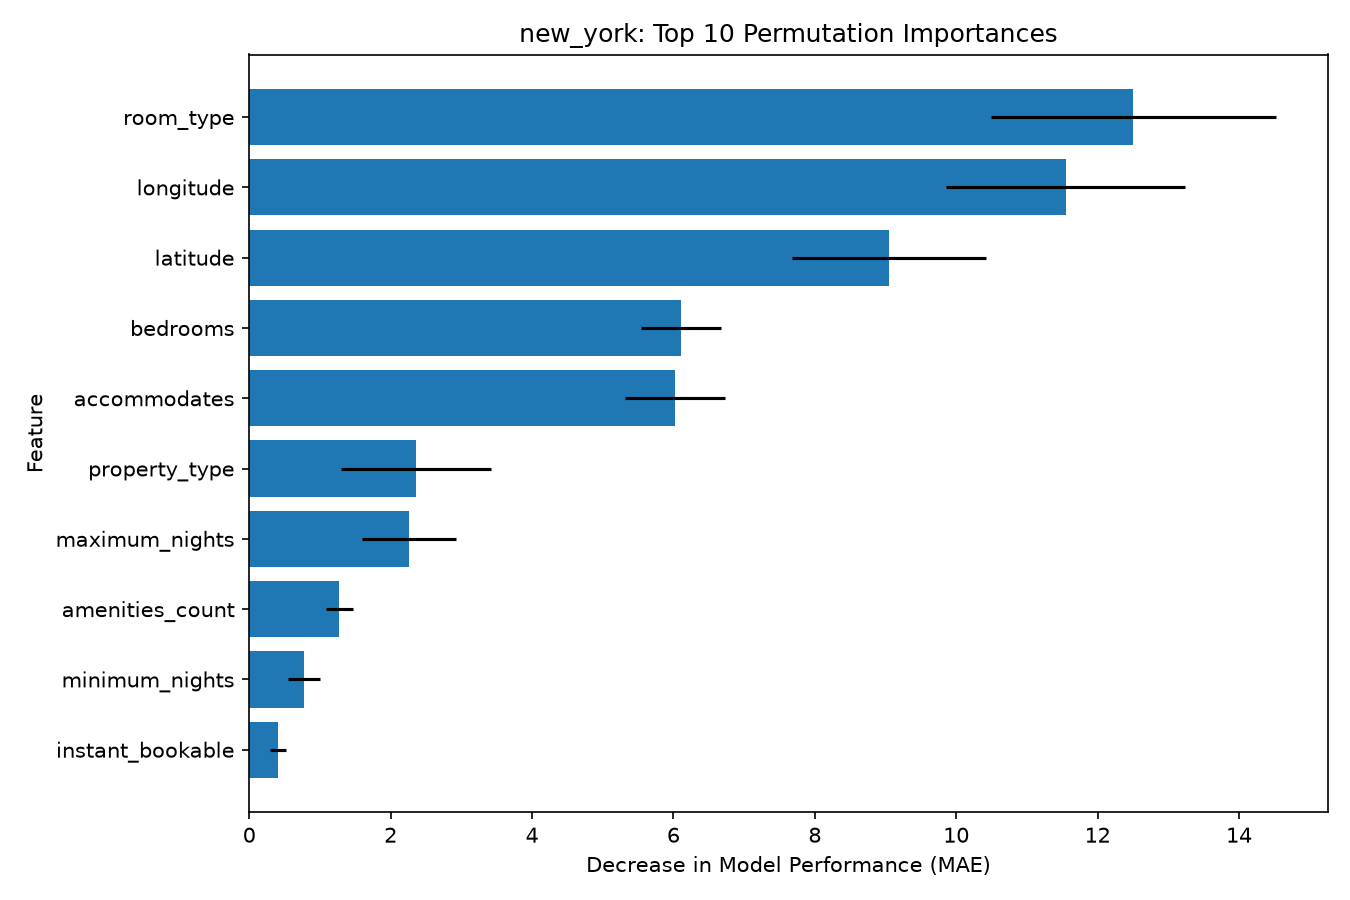

Paris — Actual vs Predicted


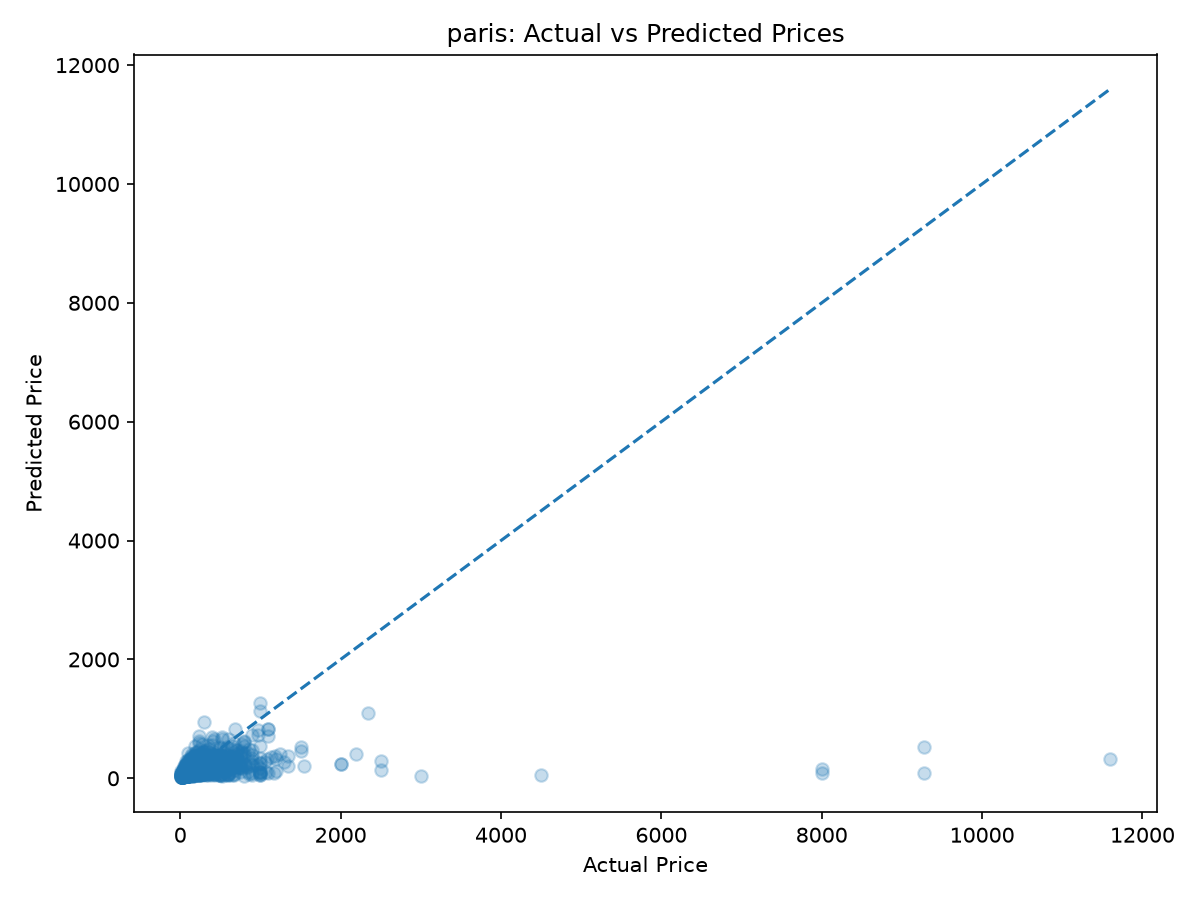

Paris — Permutation Feature Importance


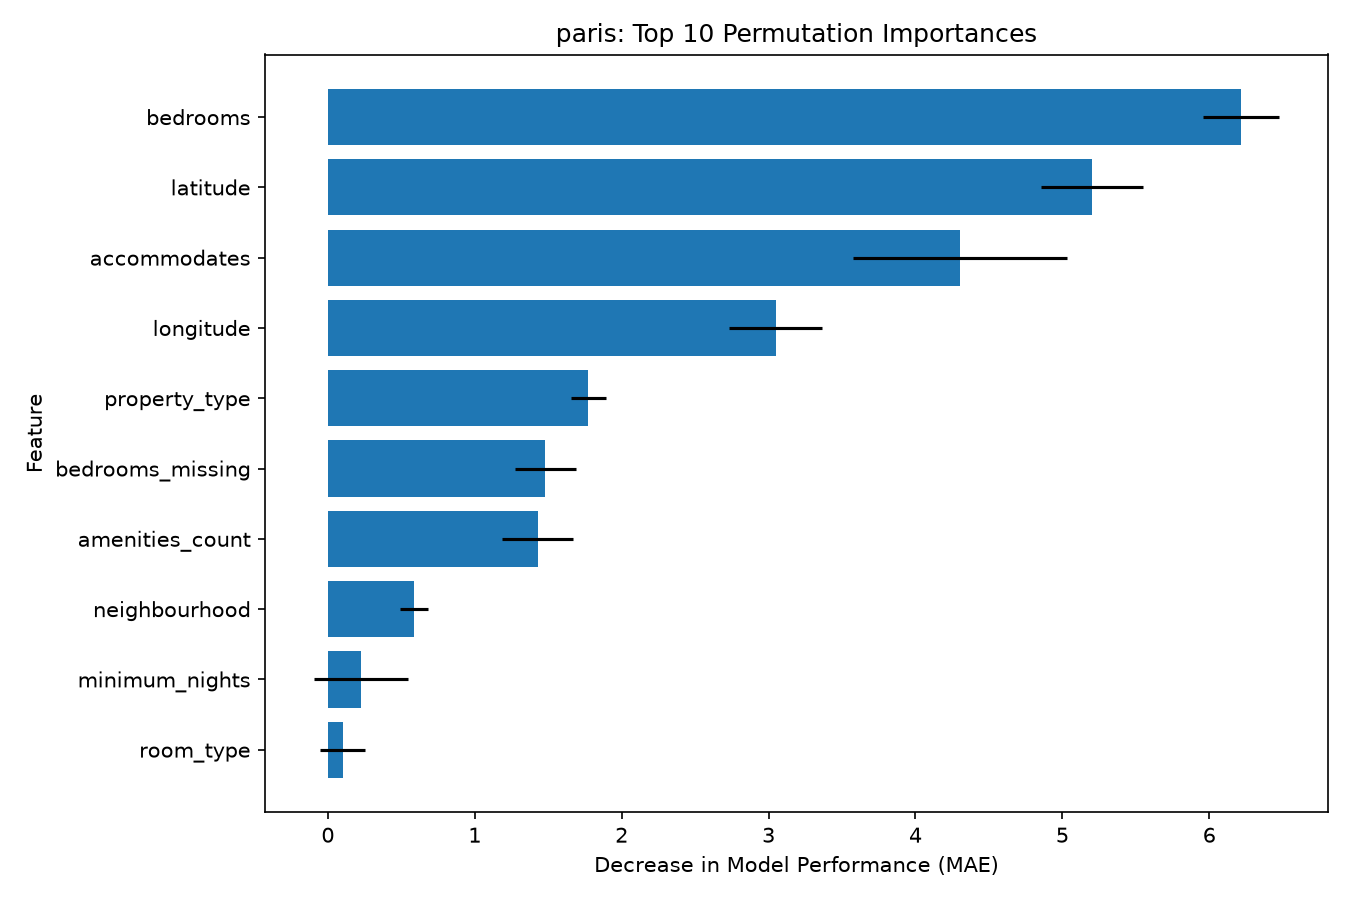

Rio De Janeiro — Actual vs Predicted


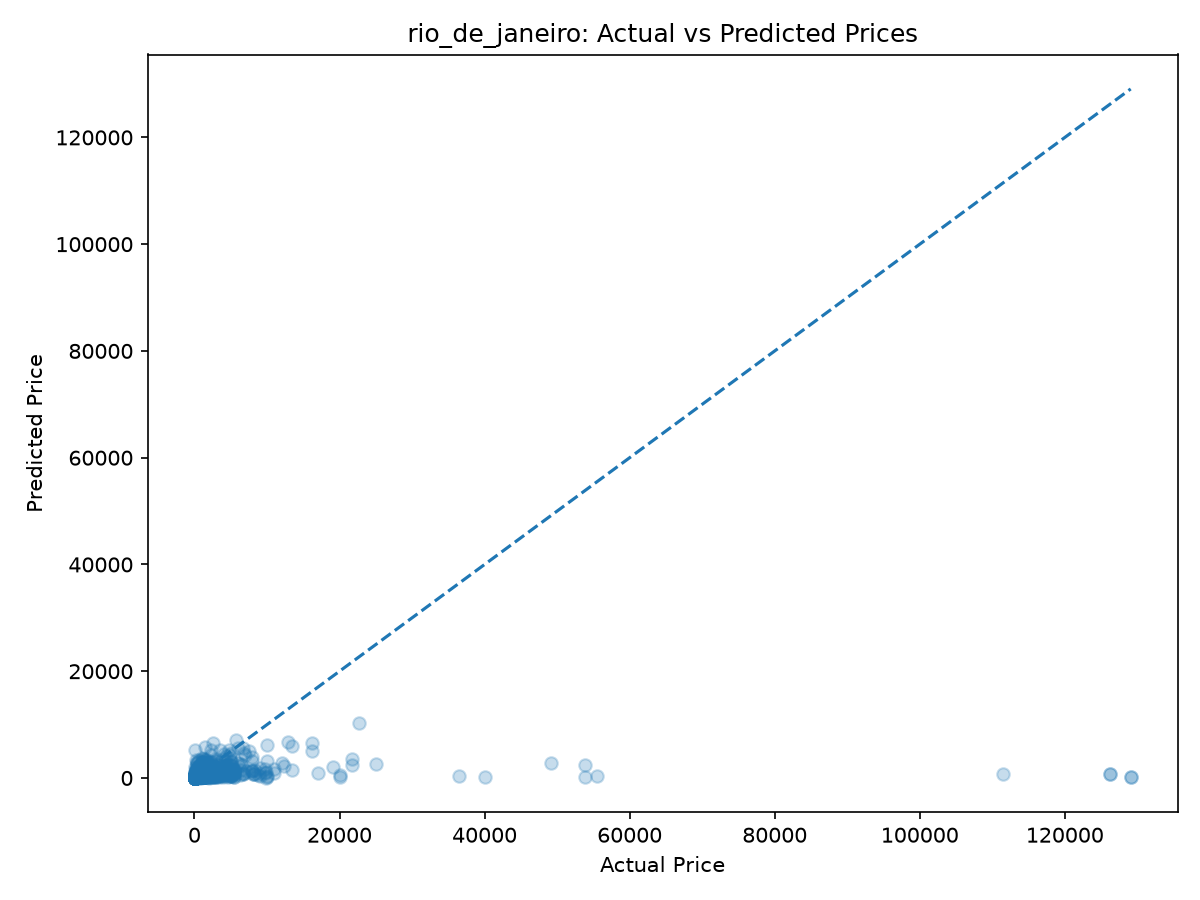

Rio De Janeiro — Permutation Feature Importance


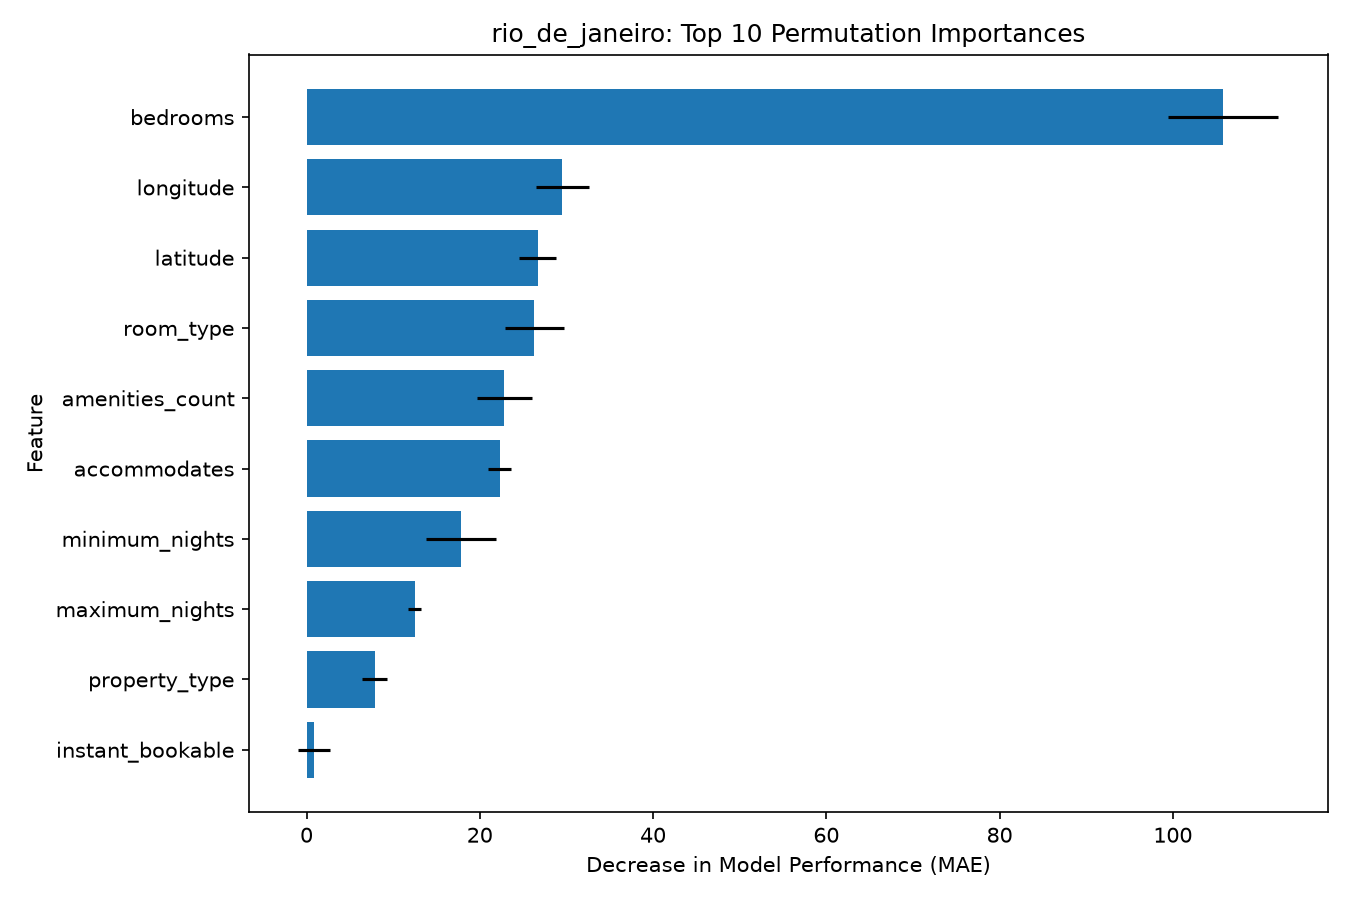

Rome — Actual vs Predicted


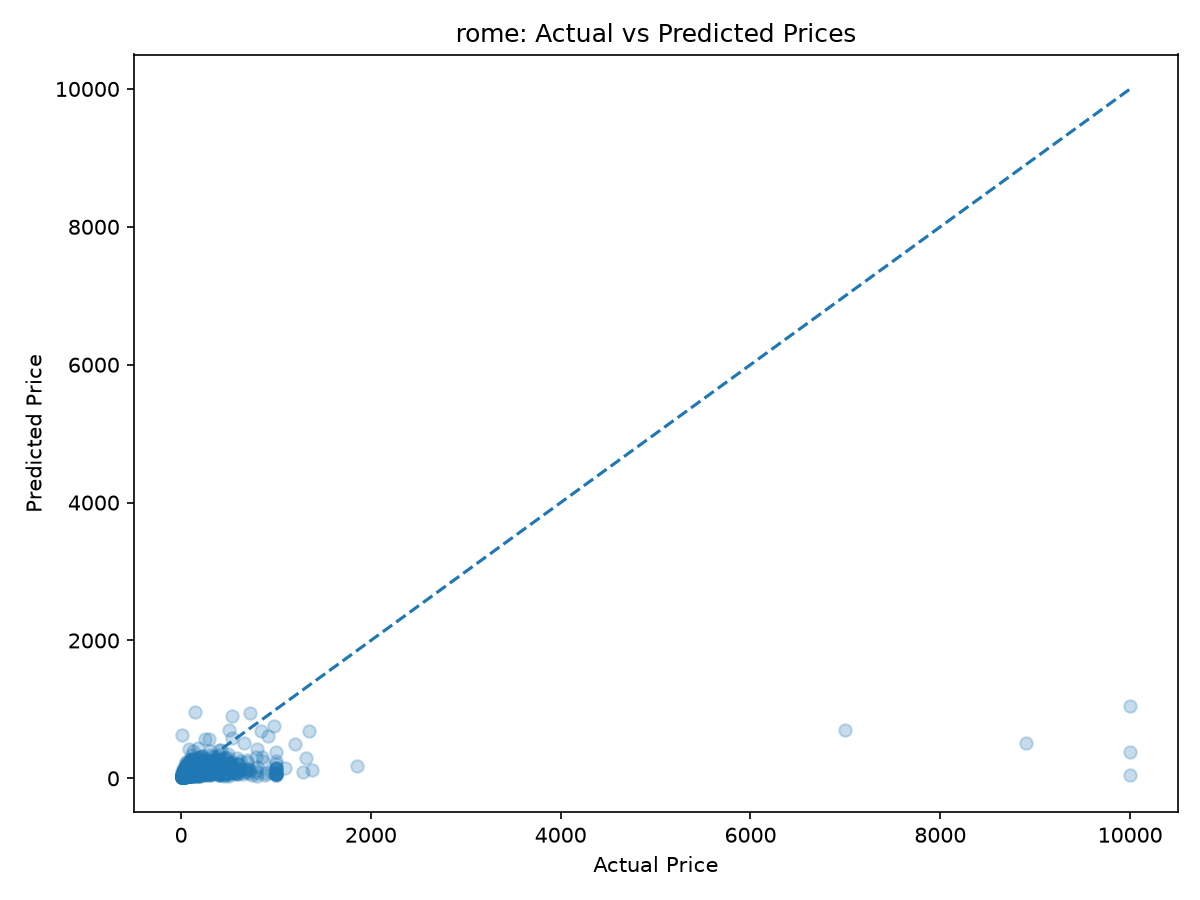

Rome — Permutation Feature Importance


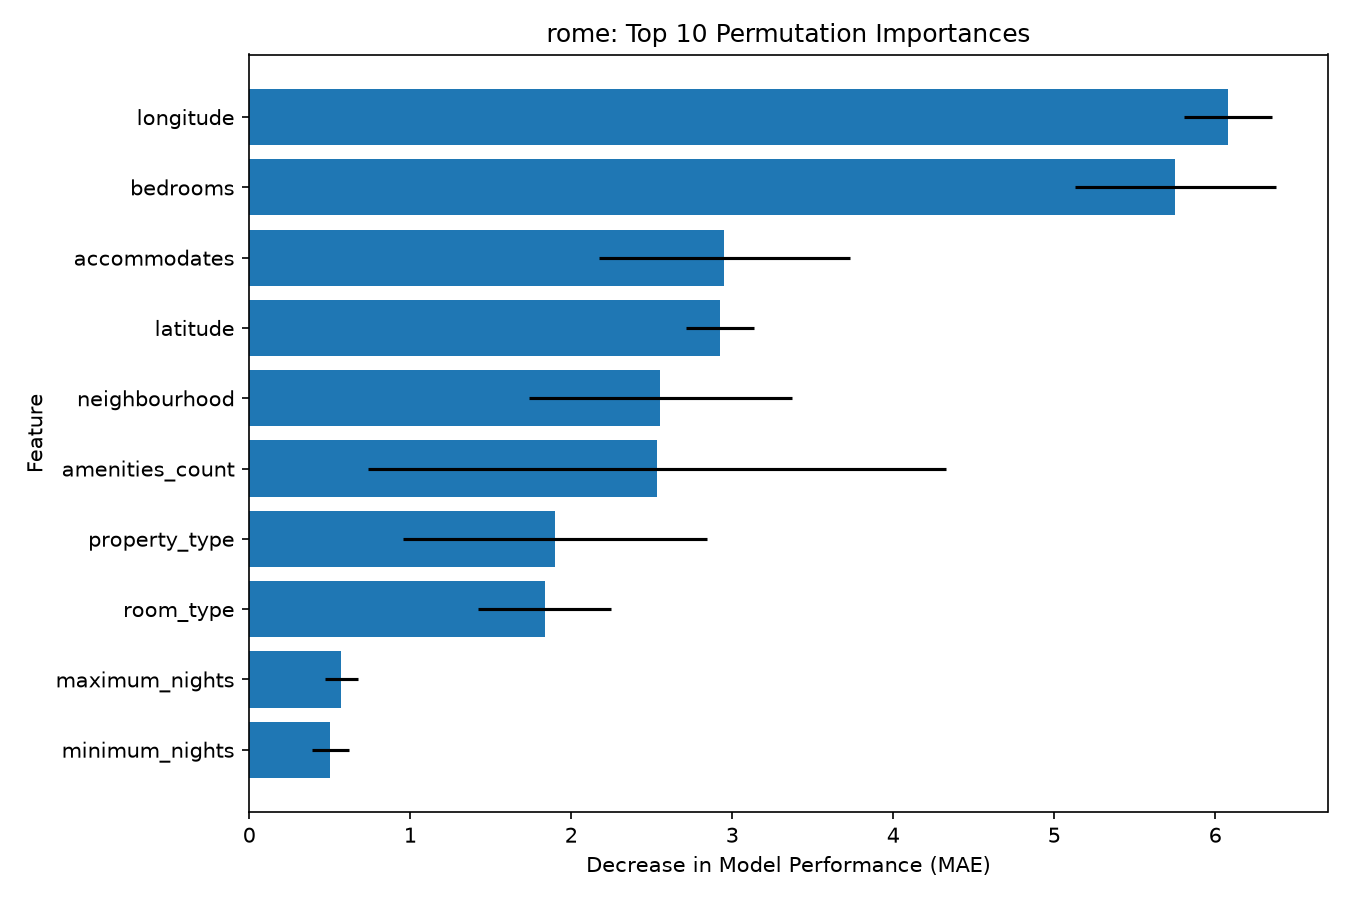

Sydney — Actual vs Predicted


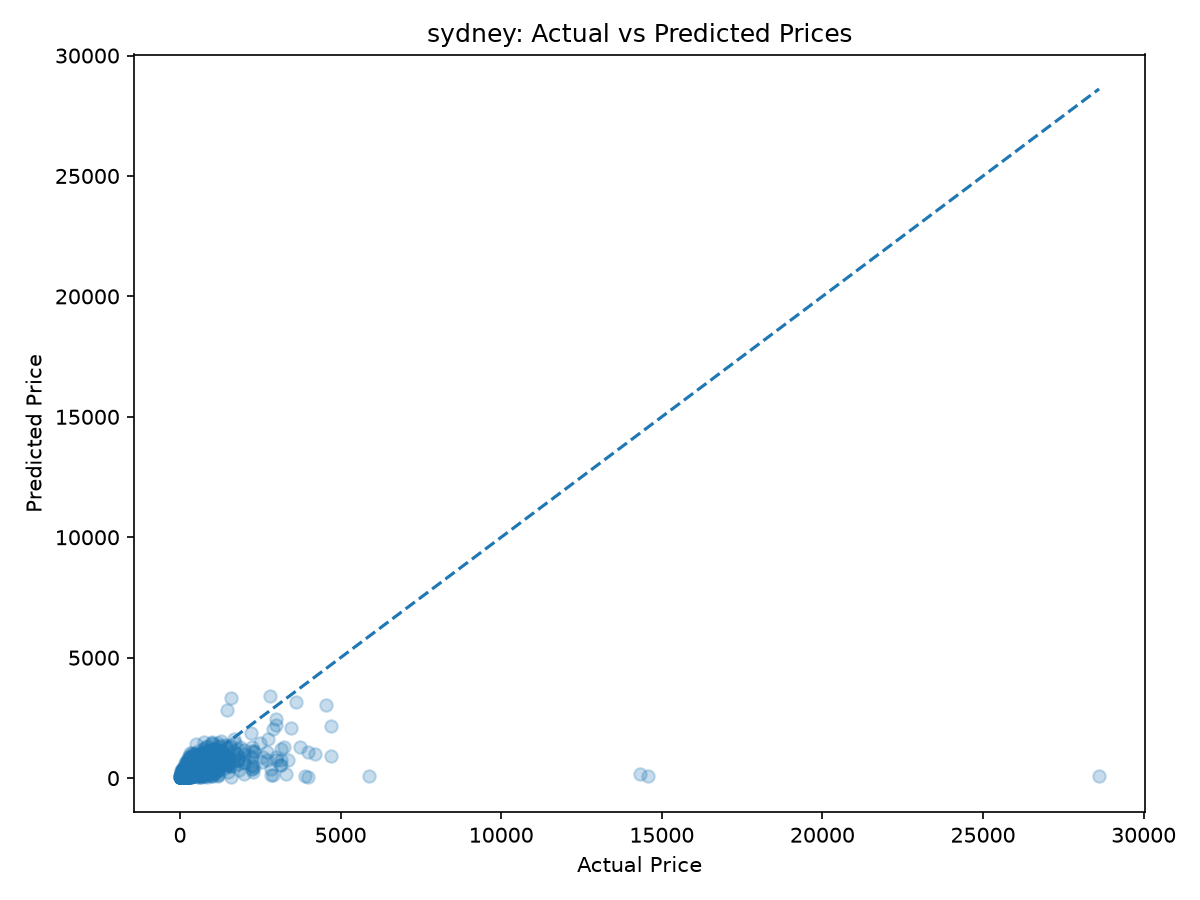

Sydney — Permutation Feature Importance


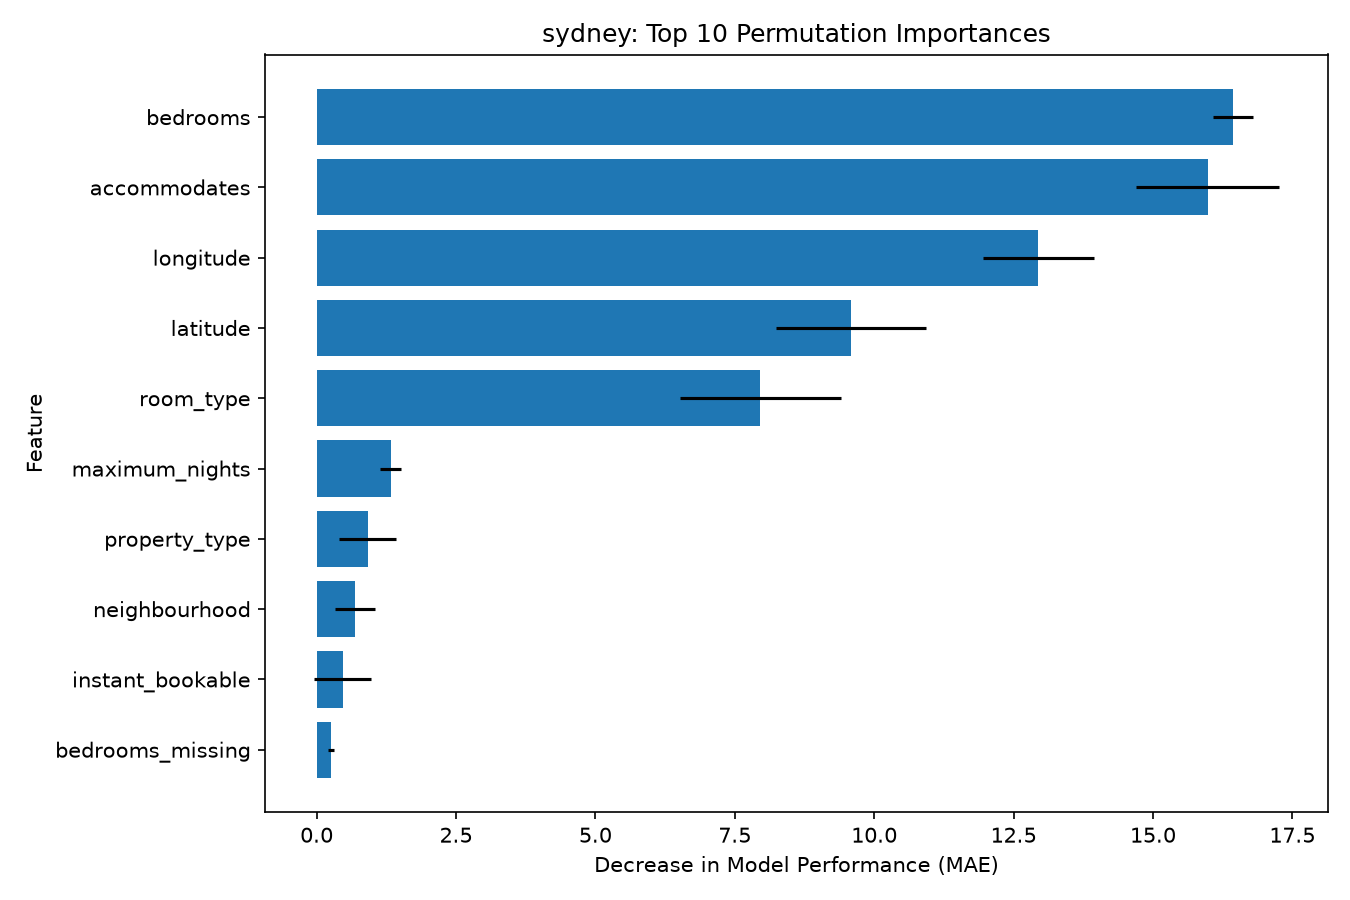

In [11]:
cities = [
    "bangkok", "cape_town", "hong_kong", "istanbul", "mexico_city",
    "new_york", "paris", "rio_de_janeiro", "rome", "sydney"
]
figure_dir = error_dir / "figures"

for city in cities:
    for suffix, label in [
        ("actual_vs_predicted", "Actual vs Predicted"),
        ("feature_importance", "Permutation Feature Importance"),
    ]:
        path = figure_dir / f"{city}_{suffix}.png"
        if path.exists():
            print(f"{city.replace('_', ' ').title()} — {label}")
            display(Image(filename=str(path), width=800))
        else:
            print("Figure not found:", path)

## 11. Inference demonstration

The project includes a prediction script and saved city-specific final model artifacts. The example prediction and reproducibility reports are displayed here.

The inference interface selects a model using the city and returns a prediction in the city's local currency. The prediction is an estimate, not a guaranteed market price.

The saved final models are located in `models/final_models/`. Earlier candidate/best-model artifacts are also retained in `models/`; the final independent-test models are the artifacts relevant to the completed final evaluation.

In [12]:
inference_dir = REPORTS / "inference_examples"
for filename in ["example_prediction.csv", "reproducibility_results.csv"]:
    path = inference_dir / filename
    print(f"\\n--- {filename} ---")
    if path.exists():
        display(pd.read_csv(path))
    else:
        print("Not found:", path)

final_model_dir = MODELS / "final_models"
if final_model_dir.exists():
    model_files = sorted(final_model_dir.glob("*.joblib"))
    print(f"\\nFinal model artifacts found: {len(model_files)}")
    for p in model_files:
        print("-", p.name)
else:
    print("Final model directory not found:", final_model_dir)

\n--- example_prediction.csv ---


,city,predicted_price,currency
0,Paris,99.009782,EUR


\n--- reproducibility_results.csv ---


,city,test_records,maximum_absolute_difference,mean_absolute_difference,reproducibility_passed
0,Bangkok,3872,8.731149e-11,1.284967e-12,True
1,Cape Town,3818,1.309672e-10,1.530983e-12,True
2,Hong Kong,1418,1.637090e-11,2.937779e-13,True
3,Istanbul,4904,1.455192e-11,2.075556e-13,True
4,Mexico City,4012,4.365575e-11,6.377458e-13,True
5,New York,7397,2.728484e-12,4.679477e-14,True
6,Paris,12926,2.273737e-13,2.182311e-15,True
7,Rio de Janeiro,5322,1.182343e-11,2.918072e-13,True
8,Rome,5529,1.250555e-12,3.444892e-14,True
9,Sydney,6726,4.547474e-13,4.257869e-15,True


\nFinal model artifacts found: 10
- bangkok_final_model.joblib
- cape_town_final_model.joblib
- hong_kong_final_model.joblib
- istanbul_final_model.joblib
- mexico_city_final_model.joblib
- new_york_final_model.joblib
- paris_final_model.joblib
- rio_de_janeiro_final_model.joblib
- rome_final_model.joblib
- sydney_final_model.joblib


## 12. Reproducibility verification

The reproducibility check loaded each saved final model and regenerated predictions for the original test records. Those predictions were compared with the previously saved final-test predictions.

**Recorded result:**
- Ten city models checked.
- 55,924 test records checked.
- All ten city checks passed.
- Maximum absolute prediction difference was approximately `1.31 × 10⁻¹⁰`.

The tiny differences are consistent with floating-point numerical precision. This check verifies that the saved artifacts reproduce the original final predictions; it does not by itself establish performance on future data.

In [13]:
repro_path = inference_dir / "reproducibility_results.csv"
if repro_path.exists():
    repro = pd.read_csv(repro_path)
    display(repro)
else:
    print("Reproducibility results report not found:", repro_path)

,city,test_records,maximum_absolute_difference,mean_absolute_difference,reproducibility_passed
0,Bangkok,3872,8.731149e-11,1.284967e-12,True
1,Cape Town,3818,1.309672e-10,1.530983e-12,True
2,Hong Kong,1418,1.637090e-11,2.937779e-13,True
3,Istanbul,4904,1.455192e-11,2.075556e-13,True
4,Mexico City,4012,4.365575e-11,6.377458e-13,True
5,New York,7397,2.728484e-12,4.679477e-14,True
6,Paris,12926,2.273737e-13,2.182311e-15,True
7,Rio de Janeiro,5322,1.182343e-11,2.918072e-13,True
8,Rome,5529,1.250555e-12,3.444892e-14,True
9,Sydney,6726,4.547474e-13,4.257869e-15,True


## 13. Conclusions, recommendations and limitations

### Conclusions

This project completed an end-to-end machine learning workflow: data quality assessment, exploratory analysis, anomaly investigation, feature engineering, candidate comparison, validation, independent testing, error analysis, inference packaging and reproducibility checks.

All ten city-specific models improved on their median baseline in MAE. Performance varied substantially by city, with Cape Town achieving the strongest test R². The analysis also identified a consistent tendency to overestimate lower-priced listings and underestimate higher-priced listings.

### Recommendations for further work

1. Investigate additional market and property characteristics that may explain price variation.
2. Examine robust approaches to rare, very high-priced listings without automatically discarding legitimate premium properties.
3. Evaluate relative error alongside absolute error, especially across different price ranges.
4. Consider time-aware validation if reliable listing observation dates or market snapshots become available.
5. Reassess performance periodically as local markets and currencies change.

### Limitations

- The initial-pricing prediction scenario is an assumption, not an explicit dataset guarantee.
- The models do not account for seasonality, holidays, local events, occupancy, demand or real-time market conditions.
- The available features do not explain much of the price variation in some cities.
- Extreme prices can substantially affect RMSE.
- City-specific metrics are in different currencies and are not directly comparable.
- Grouped validation was an additional diagnostic, not a substitute for future-time or external-market validation.

### Reproducibility and source code

The original implementation is retained in `src/`. This notebook presents its methods and results without modifying those scripts. To reproduce the complete workflow from scratch, follow the numbered scripts in order, using the original datasets and the documented project environment.